# E-Waste Profit Explorer — Complete Colab Workflow
**Group 2026-AI-14 · IT3091 Machine Learning**

This notebook integrates the eight uploaded notebooks in their original analytical order. Original model grids, random seeds, preprocessing and feature comparisons are retained. Intermediate CSVs and models are created automatically in one working folder.

## Run instructions
1. Open this notebook in Google Colab with a CPU runtime.
2. Run the dependency cell **before importing libraries**. If Colab requests a restart, restart and run from the setup cell.
3. Upload only `e_waste_metal_dataset_20000_extended.csv` when prompted. No intermediate uploads are needed.
4. Use **Runtime → Run all**. Grid searches may take considerable CPU time.
5. The final cell downloads one ZIP containing all generated evidence and final models.

Previously recorded prose/results are clearly marked as historical; new outputs come from this run. Final model selection follows training CV, before test evaluation. Targets represent recorded profit and derived financial tiers. Company-source confirmation is supplied by the group and requires its original email evidence.

## Contents
1. Data understanding and EDA
2. Preprocessing
3. Feature engineering and tier definitions
4. Linear and Logistic Regression
5. Decision Tree
6. Random Forest
7. Gradient Boosting
8. Final integration and evaluation


In [1]:
%pip install -q scikit-learn==1.6.1 numpy==2.1.3 pandas==2.2.3 joblib==1.4.2 matplotlib seaborn scipy statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 8.1 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import os, sys
from IPython.display import display
WORK = Path('/content/ewaste_complete') if Path('/content').exists() else Path.cwd() / 'ewaste_complete'
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
print('Working folder:', WORK)


Working folder: /content/ewaste_complete


# E-Waste Profitability Prediction
## 01 — Data Understanding

Group: 2026-AI-14
Module: IT3091 — Machine Learning

### Primary objective
Predict the recorded profit of an e-waste item in USD.

### Secondary objective
Develop a High, Medium, or Low profit-based priority indicator
to support the primary profitability decision.

### Unit of analysis
One row represents one device/item record identified by device_id.
Whether these records represent operational batches must be
confirmed with the data provider.

### Scope limitations
The supplied dataset does not contain processing time, energy,
acid consumption, or contamination measurements.

The accounting definition of total_profit_usd and the availability
of metal-yield measurements before purchasing must be confirmed.

Libraries import

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import hashlib
import platform
import sklearn

from google.colab import files
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1


In [4]:
from pathlib import Path
available = list(Path.cwd().glob('*.csv'))
source_name = 'e_waste_metal_dataset_20000_extended.csv'
if Path(source_name).exists():
    uploaded = {source_name: Path(source_name).read_bytes()}
else:
    uploaded = files.upload()

Saving e_waste_metal_dataset_20000_extended.csv to e_waste_metal_dataset_20000_extended.csv


Load Dataset

In [5]:
csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

assert len(csv_files) == 1, "Upload exactly one CSV file."

dataset_filename = csv_files[0]

df = pd.read_csv(dataset_filename)

with open(dataset_filename, "rb") as file:
    dataset_sha256 = hashlib.sha256(file.read()).hexdigest()

print("Dataset filename:", dataset_filename)
print("Dataset shape:", df.shape)
print("SHA-256:", dataset_sha256)

display(df.head())

Dataset filename: e_waste_metal_dataset_20000_extended.csv
Dataset shape: (20000, 13)
SHA-256: e70b6ae3521a17ff47232fe9729d56aa7a6bea4a7599aec889738c6ff7534a98


,device_id,item_name,device_category,condition,weight_g,device_age_years,gold_yield_g,silver_yield_g,copper_yield_g,total_profit_usd,Acquisition_Cost_LKR,Hazardous_Flag,Casing_Material
0,DEV-00001,AMD Ryzen 7 5800X,Microprocessor,E-Waste / End-of-Life,31.05,9,0.2652,0.1661,10.68,9.25,2575.42,No,Plastic
1,DEV-00002,iPad Pro 11,Tablet,Used-Fair,489.90,6,0.0618,0.7373,42.43,3.75,26896.00,Yes,Aluminum
2,DEV-00003,Xiaomi Mi Router 4C,Wi-Fi Router,Used-Fair,329.22,4,0.0088,0.4331,23.04,0.88,2712.06,No,Plastic
3,DEV-00004,Seagate 500GB,Hard Disk Drive,Used-Good,480.40,8,0.0105,0.5577,53.26,1.56,3993.29,No,Aluminum
4,DEV-00005,AMD Ryzen 7 5800X,Microprocessor,New,52.07,8,0.3789,0.1625,5.27,33.40,7749.66,No,Plastic


Basic data quality

In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print(
    "Duplicate device IDs:",
    df["device_id"].duplicated().sum()
)

assert "total_profit_usd" in df.columns
assert df["device_id"].notna().all()
assert df["device_id"].is_unique
assert df["total_profit_usd"].notna().all()

Column names:
['device_id', 'item_name', 'device_category', 'condition', 'weight_g', 'device_age_years', 'gold_yield_g', 'silver_yield_g', 'copper_yield_g', 'total_profit_usd', 'Acquisition_Cost_LKR', 'Hazardous_Flag', 'Casing_Material']

Data types:
device_id                object
item_name                object
device_category          object
condition                object
weight_g                float64
device_age_years          int64
gold_yield_g            float64
silver_yield_g          float64
copper_yield_g          float64
total_profit_usd        float64
Acquisition_Cost_LKR    float64
Hazardous_Flag           object
Casing_Material          object
dtype: object

Missing values:
device_id               0
item_name               0
device_category         0
condition               0
weight_g                0
device_age_years        0
gold_yield_g            0
silver_yield_g          0
copper_yield_g          0
total_profit_usd        0
Acquisition_Cost_LKR    0
Hazardous_Flag  

Train/test split for detailed EDA and Preprocessing

In [7]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.copy()
test_df = test_df.copy()

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (16000, 13)
Test dataset: (4000, 13)


Data Dictionary.

In [8]:
column_details = {
    "device_id": (
        "Unique device record identifier",
        "Identifier",
        "Exclude from model inputs"
    ),
    "item_name": (
        "Device/item name",
        "Text",
        "Keep for reference; exclude initially"
    ),
    "device_category": (
        "Device category",
        "Category",
        "Candidate input"
    ),
    "condition": (
        "Recorded device condition",
        "Category",
        "Candidate input"
    ),
    "weight_g": (
        "Recorded device weight",
        "Grams",
        "Candidate input"
    ),
    "device_age_years": (
        "Recorded device age",
        "Years",
        "Candidate input"
    ),
    "gold_yield_g": (
        "Recorded gold yield; estimate/actual timing needs confirmation",
        "Grams",
        "Input only if available before the decision"
    ),
    "silver_yield_g": (
        "Recorded silver yield; estimate/actual timing needs confirmation",
        "Grams",
        "Input only if available before the decision"
    ),
    "copper_yield_g": (
        "Recorded copper yield; estimate/actual timing needs confirmation",
        "Grams",
        "Input only if available before the decision"
    ),
    "total_profit_usd": (
        "Recorded profit; accounting definition needs confirmation",
        "USD",
        "Regression target"
    ),
    "Acquisition_Cost_LKR": (
        "Recorded acquisition cost",
        "LKR",
        "Input availability depends on decision stage"
    ),
    "Hazardous_Flag": (
        "Recorded hazardous indicator",
        "Category",
        "Candidate input; verify definition"
    ),
    "Casing_Material": (
        "Recorded casing material",
        "Category",
        "Candidate input"
    )
}

data_dictionary = pd.DataFrame([
    {
        "Column": column,
        "Description": column_details[column][0],
        "Unit_or_Type": column_details[column][1],
        "Role": column_details[column][2],
        "Data_Type": str(train_df[column].dtype),
        "Missing_Train": train_df[column].isna().sum(),
        "Unique_Train": train_df[column].nunique()
    }
    for column in train_df.columns
])

display(data_dictionary)

data_dictionary.to_csv(
    "data_dictionary.csv",
    index=False
)

,Column,Description,Unit_or_Type,Role,Data_Type,Missing_Train,Unique_Train
0,device_id,Unique device record identifier,Identifier,Exclude from model inputs,object,0,16000
1,item_name,Device/item name,Text,Keep for reference; exclude initially,object,0,57
2,device_category,Device category,Category,Candidate input,object,0,10
3,condition,Recorded device condition,Category,Candidate input,object,0,5
4,weight_g,Recorded device weight,Grams,Candidate input,float64,0,13134
5,device_age_years,Recorded device age,Years,Candidate input,int64,0,10
6,gold_yield_g,Recorded gold yield; estimate/actual timing ne...,Grams,Input only if available before the decision,float64,0,4005
7,silver_yield_g,Recorded silver yield; estimate/actual timing ...,Grams,Input only if available before the decision,float64,0,9066
8,copper_yield_g,Recorded copper yield; estimate/actual timing ...,Grams,Input only if available before the decision,float64,0,8203
9,total_profit_usd,Recorded profit; accounting definition needs c...,USD,Regression target,float64,0,3447


Summary statistics

In [9]:
numeric_columns = train_df.select_dtypes(
    include="number"
).columns.tolist()

summary_statistics = (
    train_df[numeric_columns].describe().T
)

summary_statistics["missing_count"] = (
    train_df[numeric_columns].isna().sum()
)

display(summary_statistics)

summary_statistics.to_csv(
    "training_summary_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,max,missing_count
weight_g,16000.0,446.979458,555.101737,10.000,53.1175,342.1400,511.585000,2499.7600,0
device_age_years,16000.0,4.525375,2.878910,0.000,2.0000,5.0000,7.000000,9.0000,0
gold_yield_g,16000.0,0.145398,0.213333,0.005,0.0149,0.0328,0.241125,0.9999,0
silver_yield_g,16000.0,0.763205,0.881100,0.050,0.1940,0.4479,0.919925,3.9988,0
copper_yield_g,16000.0,63.854626,89.662130,1.000,9.6675,31.1100,67.777500,399.9600,0
total_profit_usd,16000.0,8.846666,12.967467,0.220,1.2400,2.4400,12.812500,96.6600,0
Acquisition_Cost_LKR,16000.0,14056.118031,19820.346660,125.200,2686.3525,6793.3050,17518.822500,179914.8000,0


Category and condition counts


device_category


,column,value,count,percentage
0,device_category,Smartphone,1671,10.44
1,device_category,Smartwatch,1646,10.29
2,device_category,Microprocessor,1616,10.10
3,device_category,RAM Module,1597,9.98
4,device_category,Wi-Fi Router,1594,9.96
5,device_category,Desktop Motherboard,1590,9.94
6,device_category,Digital Camera,1579,9.87
7,device_category,Hard Disk Drive,1578,9.86
8,device_category,Tablet,1571,9.82
9,device_category,Laptop,1558,9.74



condition


,column,value,count,percentage
0,condition,Used-Good,4815,30.09
1,condition,Used-Fair,4740,29.62
2,condition,E-Waste / End-of-Life,3229,20.18
3,condition,Refurbished,2454,15.34
4,condition,New,762,4.76



Hazardous_Flag


,column,value,count,percentage
0,Hazardous_Flag,Yes,8756,54.72
1,Hazardous_Flag,No,7244,45.28



Casing_Material


,column,value,count,percentage
0,Casing_Material,Mixed Metal,6204,38.78
1,Casing_Material,Plastic,5115,31.97
2,Casing_Material,Aluminum,4681,29.26


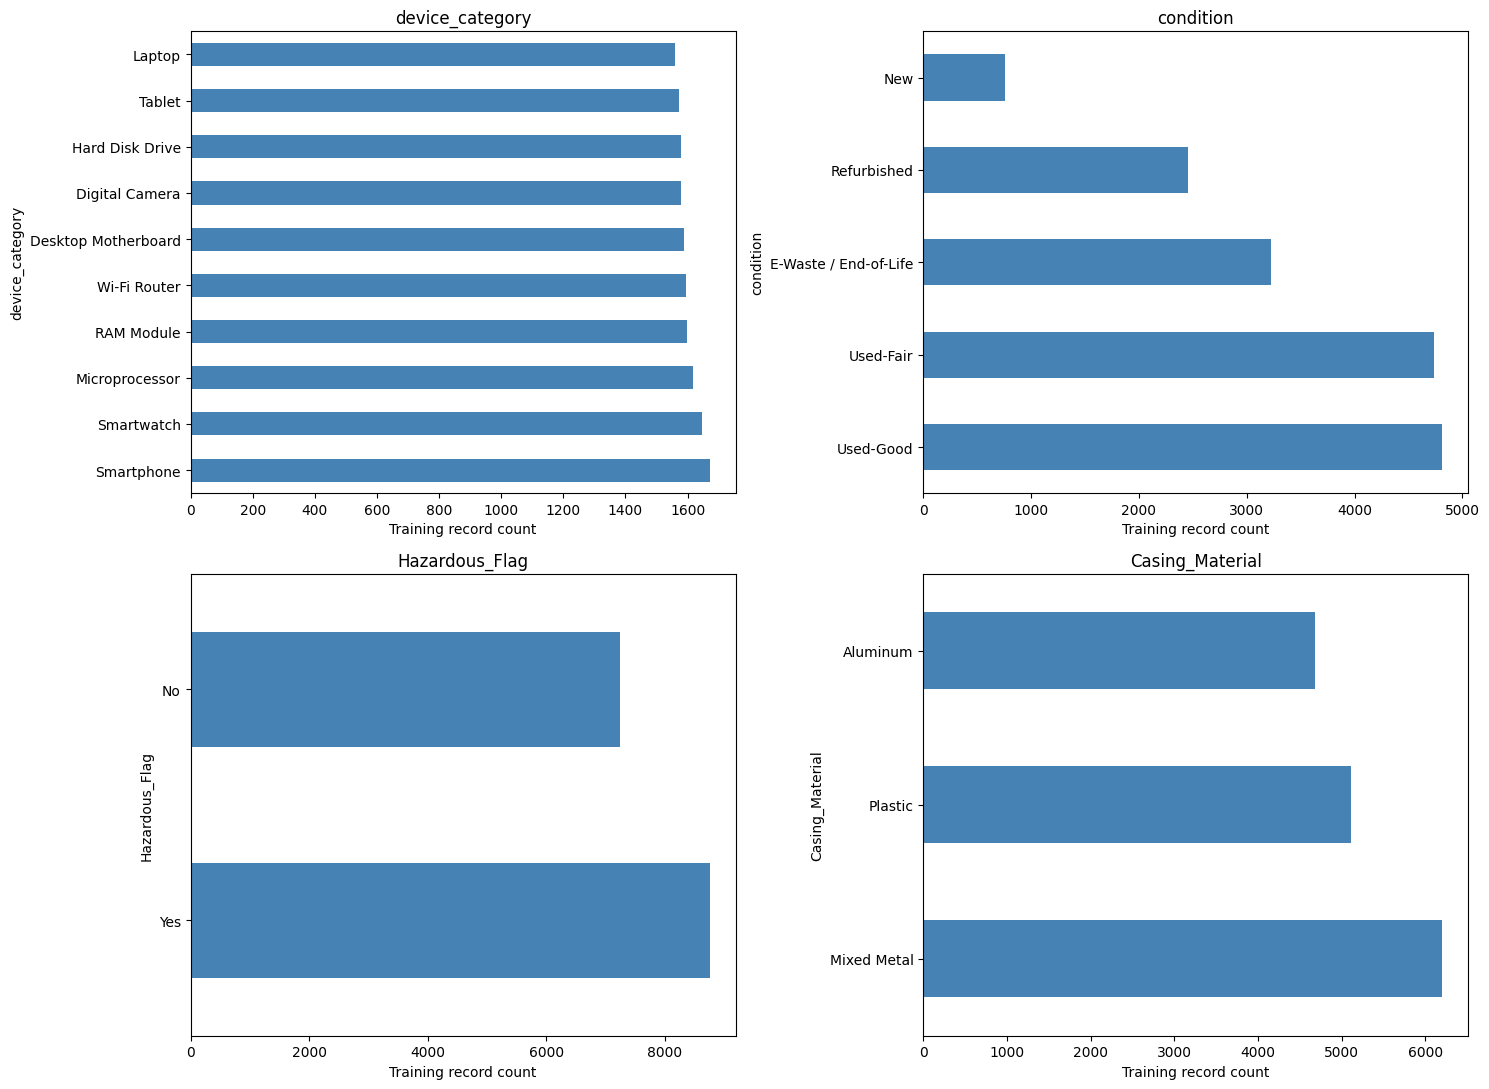

In [10]:
categorical_columns = [
    "device_category",
    "condition",
    "Hazardous_Flag",
    "Casing_Material"
]

category_count_tables = []

for column in categorical_columns:
    counts = (
        train_df[column]
        .value_counts(dropna=False)
        .rename_axis("value")
        .reset_index(name="count")
    )

    counts["percentage"] = (
        counts["count"] / len(train_df) * 100
    ).round(2)

    counts.insert(0, "column", column)
    category_count_tables.append(counts)

    print(f"\n{column}")
    display(counts)

category_counts = pd.concat(
    category_count_tables,
    ignore_index=True
)

category_counts.to_csv(
    "training_category_counts.csv",
    index=False
)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for column, ax in zip(
    categorical_columns,
    axes.flatten()
):
    counts = train_df[column].value_counts()
    counts.plot.barh(ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_xlabel("Training record count")

plt.tight_layout()
plt.savefig("category_counts.png", dpi=150)
plt.show()

Numerical distributions and skewness

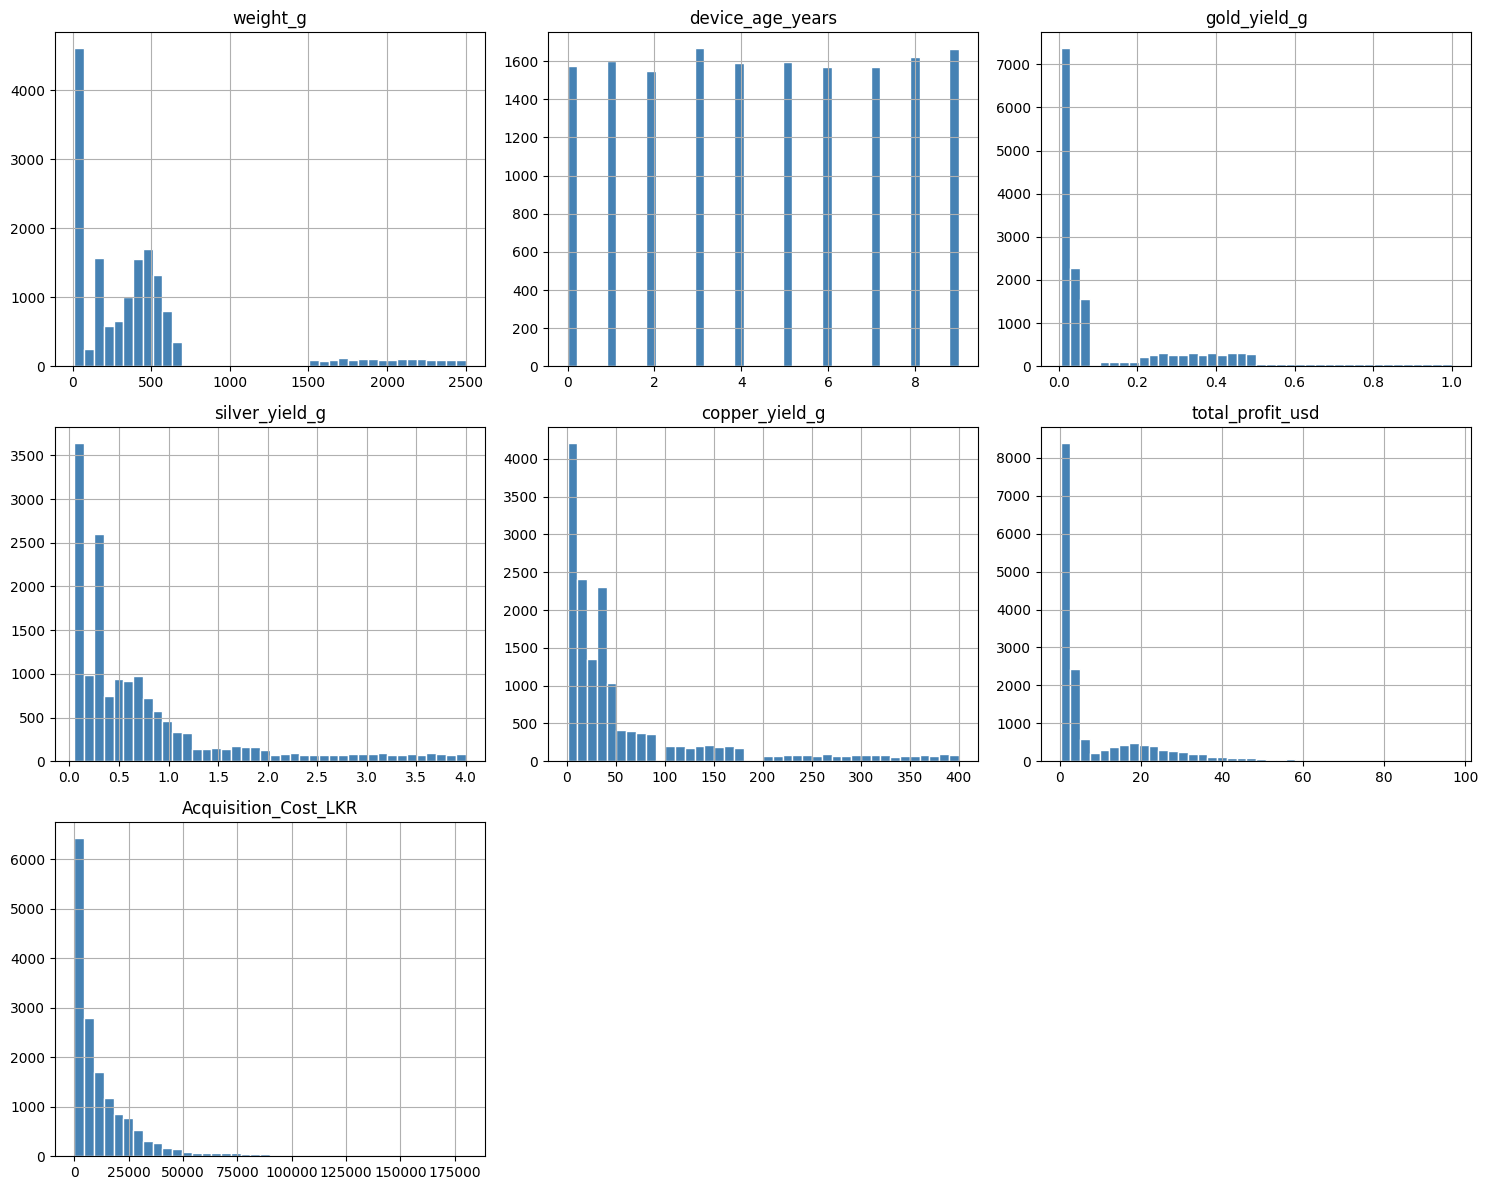

,skewness,absolute_skewness
Acquisition_Cost_LKR,3.191254,3.191254
weight_g,2.215069,2.215069
total_profit_usd,2.162711,2.162711
copper_yield_g,2.114143,2.114143
silver_yield_g,1.901334,1.901334
gold_yield_g,1.870113,1.870113
device_age_years,-0.001941,0.001941


In [11]:
train_df[numeric_columns].hist(
    bins=40,
    figsize=(15, 12),
    color="steelblue",
    edgecolor="white"
)

plt.tight_layout()
plt.savefig("numerical_distributions.png", dpi=150)
plt.show()

skewness_table = (
    train_df[numeric_columns]
    .skew()
    .rename("skewness")
    .to_frame()
)

skewness_table["absolute_skewness"] = (
    skewness_table["skewness"].abs()
)

skewness_table = skewness_table.sort_values(
    "absolute_skewness",
    ascending=False
)

display(skewness_table)

skewness_table.to_csv("training_skewness.csv")

Profit distribution and category  profit

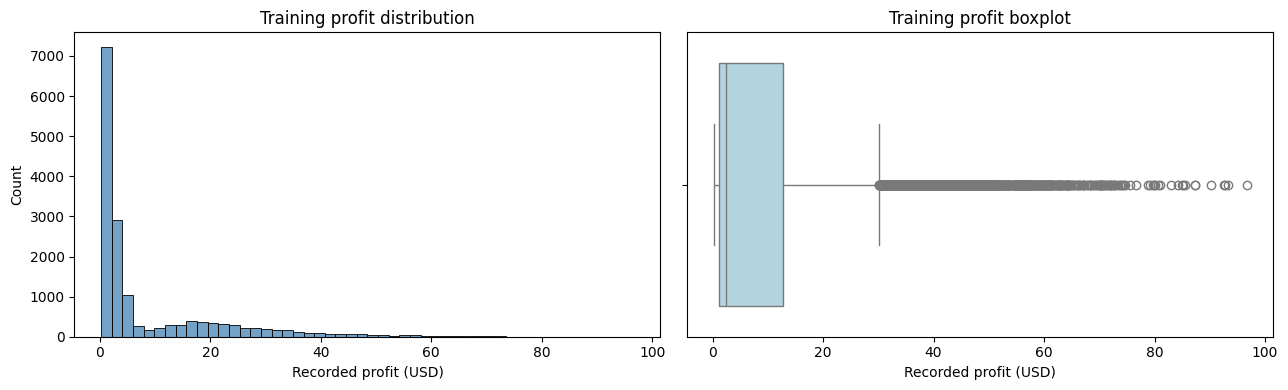

Negative-profit records: 0
Zero-profit records: 0


,count,mean,median,std,min,max
device_category,,,,,,
Desktop Motherboard,1590,36.378440,34.330,15.292893,10.68,96.66
Laptop,1558,22.247035,20.690,7.718276,8.81,51.92
Microprocessor,1616,16.478942,15.455,7.784998,3.46,45.86
Tablet,1571,4.235939,4.150,1.180657,2.12,8.67
Digital Camera,1579,3.220874,3.120,0.981119,1.52,6.99
Smartphone,1671,1.920281,1.860,0.522344,1.02,3.70
Hard Disk Drive,1578,1.887649,1.820,0.537469,0.91,3.88
RAM Module,1597,1.283369,1.240,0.400505,0.54,2.82
Wi-Fi Router,1594,1.033595,0.990,0.328129,0.43,2.31


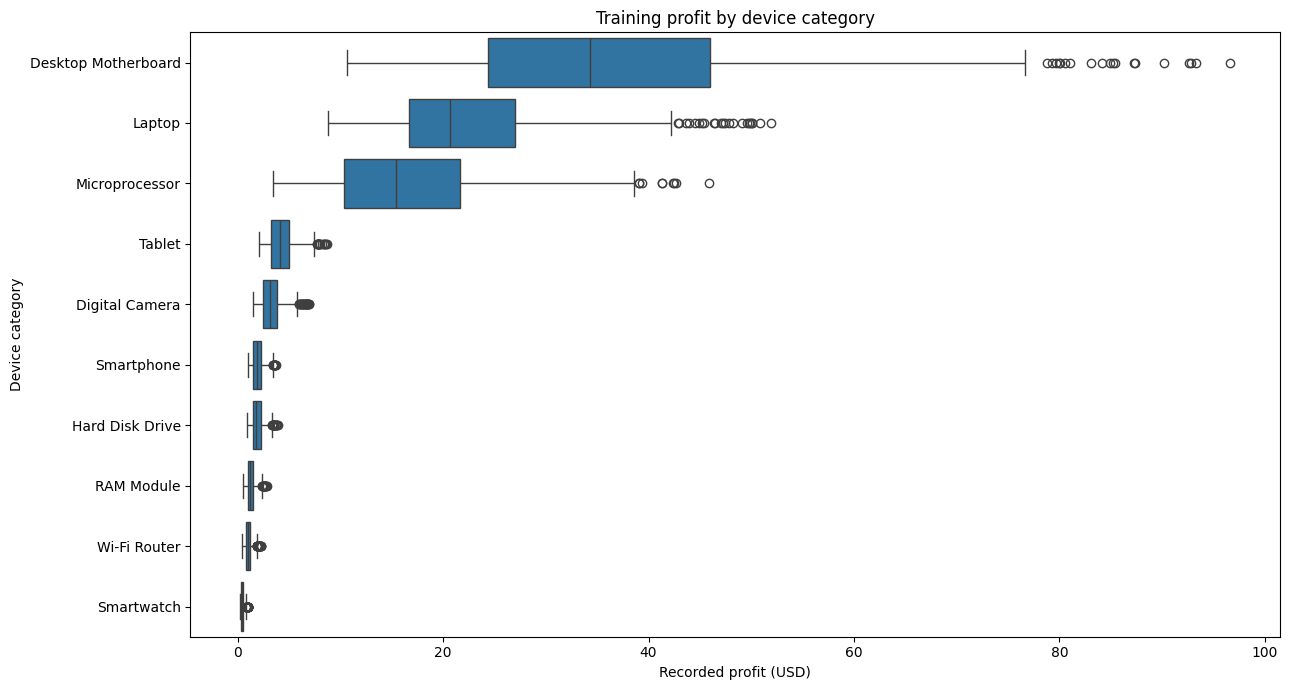

In [12]:
profit = train_df["total_profit_usd"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    profit,
    bins=50,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Training profit distribution")
axes[0].set_xlabel("Recorded profit (USD)")

sns.boxplot(
    x=profit,
    ax=axes[1],
    color="lightblue"
)
axes[1].set_title("Training profit boxplot")
axes[1].set_xlabel("Recorded profit (USD)")

plt.tight_layout()
plt.savefig("profit_distribution.png", dpi=150)
plt.show()

print("Negative-profit records:", int((profit < 0).sum()))
print("Zero-profit records:", int((profit == 0).sum()))

category_profit = (
    train_df.groupby("device_category")["total_profit_usd"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("median", ascending=False)
)

display(category_profit)

category_profit.to_csv("training_category_profit.csv")

order = category_profit.index.tolist()

plt.figure(figsize=(13, 7))

sns.boxplot(
    data=train_df,
    x="total_profit_usd",
    y="device_category",
    order=order
)

plt.xlabel("Recorded profit (USD)")
plt.ylabel("Device category")
plt.title("Training profit by device category")
plt.tight_layout()
plt.savefig("profit_by_category.png", dpi=150)
plt.show()

Outliers and physical plausibility

In [13]:
outlier_rows = []

for column in numeric_columns:
    values = train_df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (
        (train_df[column] < lower) |
        (train_df[column] > upper)
    )

    outlier_rows.append({
        "feature": column,
        "lower_bound": lower,
        "upper_bound": upper,
        "flagged_count": int(flagged.sum()),
        "flagged_percentage": round(
            flagged.mean() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_rows)

display(outlier_summary)

outlier_summary.to_csv(
    "training_iqr_flags.csv",
    index=False
)

,feature,lower_bound,upper_bound,flagged_count,flagged_percentage
0,weight_g,-634.583750,1199.286250,1558,9.74
1,device_age_years,-5.500000,14.500000,0,0.00
2,gold_yield_g,-0.324437,0.580462,861,5.38
3,silver_yield_g,-0.894887,2.008812,1585,9.91
4,copper_yield_g,-77.497500,154.942500,2042,12.76
5,total_profit_usd,-16.118750,30.171250,1301,8.13
6,Acquisition_Cost_LKR,-19562.352500,39767.527500,1166,7.29


measurement consistency

In [14]:
metal_columns = [
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g"
]

measurement_columns = [
    "weight_g",
    "device_age_years",
    "Acquisition_Cost_LKR"
] + metal_columns

negative_measurement = (
    train_df[measurement_columns] < 0
).any(axis=1)

invalid_weight = train_df["weight_g"] <= 0

total_metal_g = train_df[metal_columns].sum(
    axis=1,
    min_count=len(metal_columns)
)

metal_exceeds_weight = (
    total_metal_g > train_df["weight_g"]
)

nonfinite_numeric = ~np.isfinite(
    train_df[numeric_columns]
).all(axis=1)

plausibility_summary = pd.DataFrame({
    "check": [
        "Negative input measurement",
        "Zero or negative weight",
        "Total metal yield exceeds device weight",
        "Missing or non-finite numeric value"
    ],
    "flagged_count": [
        int(negative_measurement.sum()),
        int(invalid_weight.sum()),
        int(metal_exceeds_weight.sum()),
        int(nonfinite_numeric.sum())
    ]
})

display(plausibility_summary)

plausibility_summary.to_csv(
    "physical_plausibility_summary.csv",
    index=False
)

flagged_records = train_df.loc[
    negative_measurement |
    invalid_weight |
    metal_exceeds_weight |
    nonfinite_numeric
].copy()

flagged_records.to_csv(
    "records_for_source_review.csv",
    index=False
)

display(flagged_records.head(10))

,check,flagged_count
0,Negative input measurement,0
1,Zero or negative weight,0
2,Total metal yield exceeds device weight,0
3,Missing or non-finite numeric value,0


,device_id,item_name,device_category,condition,weight_g,device_age_years,gold_yield_g,silver_yield_g,copper_yield_g,total_profit_usd,Acquisition_Cost_LKR,Hazardous_Flag,Casing_Material


Correlation matrix

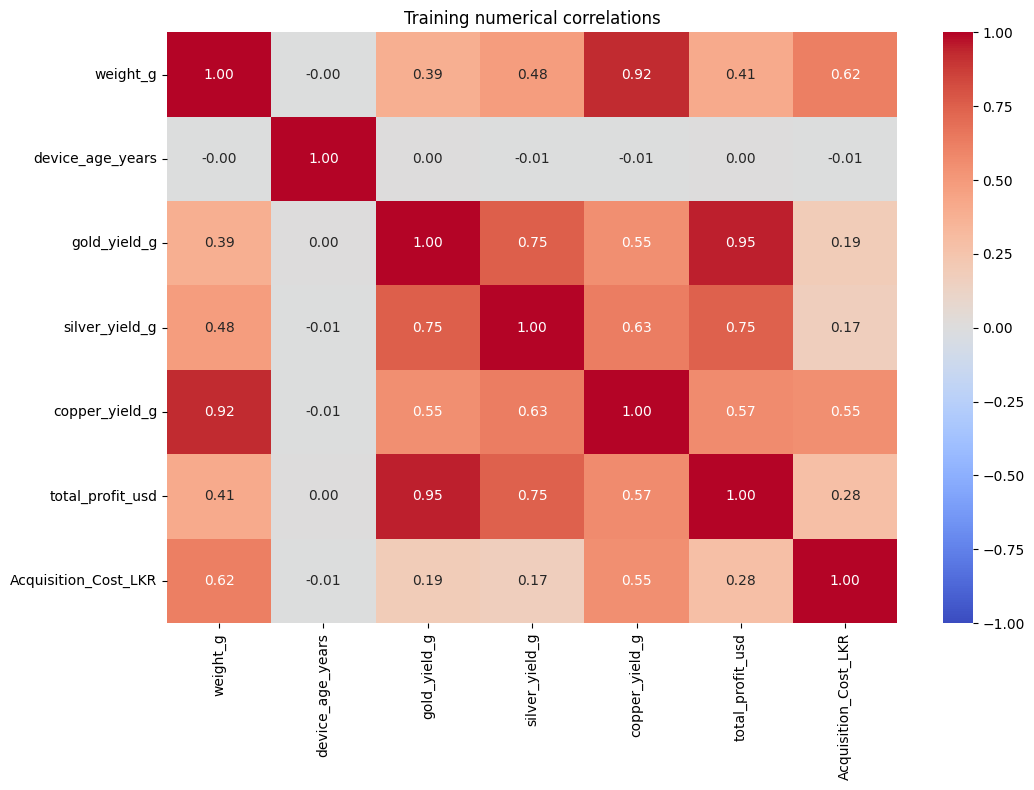

,correlation_with_profit,absolute_correlation
gold_yield_g,0.951170,0.951170
silver_yield_g,0.749136,0.749136
copper_yield_g,0.568375,0.568375
weight_g,0.412198,0.412198
Acquisition_Cost_LKR,0.284168,0.284168
device_age_years,0.001255,0.001255


In [15]:
correlation_matrix = (
    train_df[numeric_columns].corr()
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Training numerical correlations")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=150)
plt.show()

correlation_matrix.to_csv(
    "training_correlation_matrix.csv"
)

target_correlations = (
    correlation_matrix["total_profit_usd"]
    .drop("total_profit_usd")
    .rename("correlation_with_profit")
    .to_frame()
)

target_correlations["absolute_correlation"] = (
    target_correlations["correlation_with_profit"].abs()
)

target_correlations = target_correlations.sort_values(
    "absolute_correlation",
    ascending=False
)

display(target_correlations)

target_correlations.to_csv(
    "correlation_with_profit.csv"
)

Test VIF

In [16]:
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)
from statsmodels.tools.tools import add_constant

vif_features = [
    column for column in numeric_columns
    if column != "total_profit_usd"
]

vif_input = (
    train_df[vif_features]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Constant predictors cannot provide useful VIF estimates.
vif_input = vif_input.loc[
    :, vif_input.nunique() > 1
]

vif_design = add_constant(
    vif_input.astype(float),
    has_constant="add"
)

vif_table = pd.DataFrame({
    "feature": vif_input.columns,
    "VIF": [
        variance_inflation_factor(
            vif_design.to_numpy(),
            i
        )
        for i in range(1, vif_design.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print("Complete training rows used:", len(vif_input))

display(vif_table)

vif_table.to_csv(
    "training_vif.csv",
    index=False
)

Complete training rows used: 16000


,feature,VIF
4,copper_yield_g,10.734528
0,weight_g,9.094280
3,silver_yield_g,2.887590
2,gold_yield_g,2.534895
5,Acquisition_Cost_LKR,1.716412
1,device_age_years,1.000185


EDA Insight Log

In [17]:
strongest_feature = target_correlations.index[0]

strongest_correlation = target_correlations.loc[
    strongest_feature,
    "correlation_with_profit"
]

most_skewed_feature = skewness_table.index[0]

highest_median_category = category_profit.index[0]

high_vif_features = vif_table.loc[
    vif_table["VIF"] > 5,
    "feature"
].tolist()

profit_flag_count = int(
    outlier_summary.loc[
        outlier_summary["feature"] == "total_profit_usd",
        "flagged_count"
    ].iloc[0]
)

eda_insight_log = pd.DataFrame([
    {
        "topic": "Target distribution",
        "observed_evidence": (
            f"Profit skewness = {profit.skew():.3f}; "
            f"IQR-flagged records = {profit_flag_count}"
        ),
        "modeling_implication": (
            "Compare MAE and RMSE; review large errors; "
            "retain valid high-value records."
        )
    },
    {
        "topic": "Numerical skewness",
        "observed_evidence": (
            f"Highest absolute skewness: {most_skewed_feature}"
        ),
        "modeling_implication": (
            "Consider justified transformations in feature "
            "engineering and compare validation performance."
        )
    },
    {
        "topic": "Profit association",
        "observed_evidence": (
            f"Strongest absolute numerical correlation: "
            f"{strongest_feature}, r={strongest_correlation:.3f}"
        ),
        "modeling_implication": (
            "Useful candidate predictor; verify availability "
            "before the business decision. Association is not causation."
        )
    },
    {
        "topic": "Multicollinearity",
        "observed_evidence": (
            f"Numerical predictors with VIF > 5: {high_vif_features}"
        ),
        "modeling_implication": (
            "Interpret linear coefficients cautiously; "
            "do not automatically delete predictors."
        )
    },
    {
        "topic": "Category differences",
        "observed_evidence": (
            f"Highest median recorded profit category: "
            f"{highest_median_category}"
        ),
        "modeling_implication": (
            "Include category as a candidate input and "
            "evaluate errors separately by category."
        )
    },
    {
        "topic": "Loss examples",
        "observed_evidence": (
            f"Negative-profit training records: "
            f"{int((profit < 0).sum())}"
        ),
        "modeling_implication": (
            "If absent, loss-detection performance cannot "
            "be validated using this sample."
        )
    },
    {
        "topic": "Physical consistency",
        "observed_evidence": (
            f"Metal yield exceeds weight in "
            f"{int(metal_exceeds_weight.sum())} training records"
        ),
        "modeling_implication": (
            "Confirm units and measurement definitions "
            "with the provider before cleaning."
        )
    }
])

display(eda_insight_log)

eda_insight_log.to_csv(
    "eda_insight_log.csv",
    index=False
)

,topic,observed_evidence,modeling_implication
0,Target distribution,Profit skewness = 2.163; IQR-flagged records =...,Compare MAE and RMSE; review large errors; ret...
1,Numerical skewness,Highest absolute skewness: Acquisition_Cost_LKR,Consider justified transformations in feature ...
2,Profit association,Strongest absolute numerical correlation: gold...,Useful candidate predictor; verify availabilit...
3,Multicollinearity,Numerical predictors with VIF > 5: ['copper_yi...,Interpret linear coefficients cautiously; do n...
4,Category differences,Highest median recorded profit category: Deskt...,Include category as a candidate input and eval...
5,Loss examples,Negative-profit training records: 0,"If absent, loss-detection performance cannot b..."
6,Physical consistency,Metal yield exceeds weight in 0 training records,Confirm units and measurement definitions with...


Source and limitations

## Data provenance and limitations

### Source verification
- Data provider: Pending confirmation/evidence.
- Collection method and collection period: Pending confirmation.
- Permission and anonymisation: Pending supporting evidence.
- Industry Explorer scope approval: Pending supporting evidence.
- Stakeholder feedback: To be collected after evaluation.

### Unit of analysis
The CSV identifies device/item records using device_id.
The proposal describes batches. The group must confirm the
relationship between item records and operational batches.

### Target definition
total_profit_usd is the recorded regression target.
Its accounting definition, including whether acquisition and
operating costs are included, requires provider confirmation.

### Input availability and leakage
Metal yields must be available as estimates before the intended
decision to qualify as predictors. Actual post-recycling yields
would not be available for a pre-purchase prediction.

Acquisition cost availability depends on the decision stage.
A final purchase price may be unavailable during initial bidding.

device_id is an identifier and will not be used as a predictor.
item_name will initially be excluded.

### Missing operational information
Processing time, energy, acid consumption and contamination
measurements are absent from the supplied CSV.

A profit-based High/Medium/Low tier is a proxy and does not
establish operational scheduling performance.

### Currency
Acquisition_Cost_LKR and total_profit_usd use different currencies.
They must not be directly subtracted without a documented,
date-appropriate exchange rate and verified accounting logic.

### Validation
The same 80/20 random split with random_state=42 will be used
across models. Detailed EDA uses training records only.

The random split does not establish performance on future
periods, new suppliers or new facilities.

### Statistical assumptions
Input distributions and VIF provide preliminary diagnostics.
Linear-model residual assumptions will be examined after fitting.

In [18]:
import json

train_df.to_csv("train_raw.csv", index=False)
test_df.to_csv("test_raw.csv", index=False)

split_manifest = pd.concat([
    train_df[["device_id"]].assign(split="train"),
    test_df[["device_id"]].assign(split="test")
], ignore_index=True)

split_manifest.to_csv(
    "split_manifest.csv",
    index=False
)

manifest = {
    "dataset_filename": dataset_filename,
    "source_sha256": dataset_sha256,
    "random_state": 42,
    "test_fraction": 0.20,
    "training_rows": len(train_df),
    "test_rows": len(test_df),
    "target": "total_profit_usd",
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

with open("dataset_manifest.json", "w") as file:
    json.dump(manifest, file, indent=2)

print("Training and test datasets saved.")
print("Original values retained; no preprocessing applied.")

Training and test datasets saved.
Original values retained; no preprocessing applied.


In [19]:
from pathlib import Path

# 02 — Data Preprocessing

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Objectives:
- Preserve the existing training/test split.
- Audit and clean invalid or inconsistent values.
- Record preprocessing decisions.
- Define fold-local imputation, encoding and scaling pipelines.
- Export cleaned training and test datasets.

The target is total_profit_usd.
No preprocessing parameters will be learned from the test dataset.

Libraries import

In [20]:
import pandas as pd
import numpy as np
import json

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

pd.set_option("display.max_columns", None)

In [21]:
required_files = ["train_raw.csv", "test_raw.csv"]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_raw = pd.read_csv("train_raw.csv")
test_raw = pd.read_csv("test_raw.csv")

print("Training shape:", train_raw.shape)
print("Test shape:", test_raw.shape)

display(train_raw.head())

Training shape: (16000, 13)
Test shape: (4000, 13)


,device_id,item_name,device_category,condition,weight_g,device_age_years,gold_yield_g,silver_yield_g,copper_yield_g,total_profit_usd,Acquisition_Cost_LKR,Hazardous_Flag,Casing_Material
0,DEV-05895,Nikon D3500,Digital Camera,Used-Fair,440.58,7,0.0304,1.1019,42.93,2.53,13242.66,Yes,Plastic
1,DEV-03729,iPhone 11,Smartphone,Used-Good,179.41,8,0.0261,0.2686,17.22,1.84,11511.64,Yes,Mixed Metal
2,DEV-08959,Samsung Galaxy Watch 4,Smartwatch,New,42.33,3,0.0096,0.0749,3.94,0.94,14879.31,Yes,Aluminum
3,DEV-07672,iPhone 13,Smartphone,Used-Fair,178.62,6,0.0255,0.3385,17.12,1.46,19217.96,No,Aluminum
4,DEV-06000,Intel Core i3-10100,Microprocessor,E-Waste / End-of-Life,59.42,4,0.4903,0.1835,12.50,17.35,1252.62,No,Mixed Metal


Split and schema consistency

In [22]:
expected_columns = [
    "device_id",
    "item_name",
    "device_category",
    "condition",
    "weight_g",
    "device_age_years",
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g",
    "total_profit_usd",
    "Acquisition_Cost_LKR",
    "Hazardous_Flag",
    "Casing_Material"
]

assert train_raw.columns.tolist() == expected_columns
assert test_raw.columns.tolist() == expected_columns

for name, dataset in [
    ("Training", train_raw),
    ("Test", test_raw)
]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

    print(
        f"{name} duplicate rows:",
        dataset.duplicated().sum()
    )

assert set(train_raw["device_id"]).isdisjoint(
    set(test_raw["device_id"])
)

assert len(train_raw) == 16000
assert len(test_raw) == 4000

print("Schema and split checks passed.")

Training duplicate rows: 0
Test duplicate rows: 0
Schema and split checks passed.


Reusable cleaning function

In [23]:
numeric_columns = [
    "weight_g",
    "device_age_years",
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g",
    "total_profit_usd",
    "Acquisition_Cost_LKR"
]

text_columns = [
    "device_id",
    "item_name",
    "device_category",
    "condition",
    "Hazardous_Flag",
    "Casing_Material"
]

nonnegative_inputs = [
    column for column in numeric_columns
    if column != "total_profit_usd"
]

def clean_dataset(dataset):
    cleaned = dataset.copy()
    audit = []

    for column in text_columns:
        original = cleaned[column].astype("string")
        stripped = original.str.strip()

        spaces_changed = int(
            original.ne(stripped).fillna(False).sum()
        )

        blank_count = int(
            stripped.eq("").fillna(False).sum()
        )

        stripped = stripped.mask(stripped.eq(""), pd.NA)

        # Use np.nan for sklearn categorical imputers.
        cleaned[column] = (
            stripped.astype(object)
            .where(stripped.notna(), np.nan)
        )

        audit.append({
            "column": column,
            "action": "Strip whitespace; blank to missing",
            "flagged_count": spaces_changed + blank_count
        })

    for column in numeric_columns:
        original = cleaned[column]
        converted = pd.to_numeric(original, errors="coerce")

        conversion_failures = int(
            (original.notna() & converted.isna()).sum()
        )

        infinite_count = int(
            converted.isin([np.inf, -np.inf]).sum()
        )

        cleaned[column] = converted.replace(
            [np.inf, -np.inf],
            np.nan
        )

        audit.append({
            "column": column,
            "action": "Numeric conversion; infinity to missing",
            "flagged_count": conversion_failures + infinite_count
        })

    for column in nonnegative_inputs:
        invalid = cleaned[column] < 0

        audit.append({
            "column": column,
            "action": "Negative physical input to missing",
            "flagged_count": int(invalid.sum())
        })

        cleaned.loc[invalid, column] = np.nan

    zero_weight = cleaned["weight_g"] == 0

    audit.append({
        "column": "weight_g",
        "action": "Zero weight to missing",
        "flagged_count": int(zero_weight.sum())
    })

    cleaned.loc[zero_weight, "weight_g"] = np.nan

    return cleaned, pd.DataFrame(audit)

Training and test datasets clean

In [24]:
train_clean, train_cleaning_audit = clean_dataset(
    train_raw
)

test_clean, test_cleaning_audit = clean_dataset(
    test_raw
)

# Missing labels cannot be filled using an input imputer.
for name, dataset in [
    ("Training", train_clean),
    ("Test", test_clean)
]:
    assert dataset["total_profit_usd"].notna().all(), (
        f"{name} has missing/invalid targets. "
        "Review these records before proceeding."
    )

    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

# Cleaning must preserve the existing records and split.
assert train_clean["device_id"].tolist() == (
    train_raw["device_id"].astype(str).str.strip().tolist()
)

assert test_clean["device_id"].tolist() == (
    test_raw["device_id"].astype(str).str.strip().tolist()
)

assert set(train_clean["device_id"]).isdisjoint(
    set(test_clean["device_id"])
)

print("Training cleaning audit:")
display(train_cleaning_audit)

print("Test cleaning audit:")
display(test_cleaning_audit)

Training cleaning audit:


,column,action,flagged_count
0,device_id,Strip whitespace; blank to missing,0
1,item_name,Strip whitespace; blank to missing,0
2,device_category,Strip whitespace; blank to missing,0
3,condition,Strip whitespace; blank to missing,0
4,Hazardous_Flag,Strip whitespace; blank to missing,0
5,Casing_Material,Strip whitespace; blank to missing,0
6,weight_g,Numeric conversion; infinity to missing,0
7,device_age_years,Numeric conversion; infinity to missing,0
8,gold_yield_g,Numeric conversion; infinity to missing,0
9,silver_yield_g,Numeric conversion; infinity to missing,0


Test cleaning audit:


,column,action,flagged_count
0,device_id,Strip whitespace; blank to missing,0
1,item_name,Strip whitespace; blank to missing,0
2,device_category,Strip whitespace; blank to missing,0
3,condition,Strip whitespace; blank to missing,0
4,Hazardous_Flag,Strip whitespace; blank to missing,0
5,Casing_Material,Strip whitespace; blank to missing,0
6,weight_g,Numeric conversion; infinity to missing,0
7,device_age_years,Numeric conversion; infinity to missing,0
8,gold_yield_g,Numeric conversion; infinity to missing,0
9,silver_yield_g,Numeric conversion; infinity to missing,0


After cleaning check missing valus

In [25]:
missing_summary = pd.DataFrame({
    "train_missing_before": train_raw.isna().sum(),
    "train_missing_after": train_clean.isna().sum(),
    "test_missing_before": test_raw.isna().sum(),
    "test_missing_after": test_clean.isna().sum()
})

display(missing_summary)

missing_summary.to_csv(
    "preprocessing_missing_summary.csv"
)

,train_missing_before,train_missing_after,test_missing_before,test_missing_after
device_id,0,0,0,0
item_name,0,0,0,0
device_category,0,0,0,0
condition,0,0,0,0
weight_g,0,0,0,0
device_age_years,0,0,0,0
gold_yield_g,0,0,0,0
silver_yield_g,0,0,0,0
copper_yield_g,0,0,0,0
total_profit_usd,0,0,0,0


Check Category consistency

In [26]:
categorical_features = [
    "device_category",
    "condition",
    "Hazardous_Flag",
    "Casing_Material"
]

category_audit_rows = []

for column in categorical_features:
    train_values = set(
        train_clean[column].dropna().unique()
    )

    test_values = set(
        test_clean[column].dropna().unique()
    )

    unseen_test_values = sorted(
        test_values - train_values
    )

    category_audit_rows.append({
        "column": column,
        "training_categories": sorted(train_values),
        "unseen_test_categories": unseen_test_values
    })

    print(f"\n{column}")
    print("Training categories:", sorted(train_values))
    print("Unseen test categories:", unseen_test_values)

category_audit = pd.DataFrame(category_audit_rows)

category_audit.to_csv(
    "category_consistency_audit.csv",
    index=False
)


device_category
Training categories: ['Desktop Motherboard', 'Digital Camera', 'Hard Disk Drive', 'Laptop', 'Microprocessor', 'RAM Module', 'Smartphone', 'Smartwatch', 'Tablet', 'Wi-Fi Router']
Unseen test categories: []

condition
Training categories: ['E-Waste / End-of-Life', 'New', 'Refurbished', 'Used-Fair', 'Used-Good']
Unseen test categories: []

Hazardous_Flag
Training categories: ['No', 'Yes']
Unseen test categories: []

Casing_Material
Training categories: ['Aluminum', 'Mixed Metal', 'Plastic']
Unseen test categories: []


Outlier decision

## Outlier handling decision

IQR flags from the Data Understanding notebook identify extreme
values, but do not establish that those records are errors.

Valid high-weight and high-profit records are retained because
they may be important to the business decision.

No target clipping or automatic IQR-based row removal is applied.

Negative physical inputs and zero weight are marked as missing.
They should also be reviewed with the data provider.

Records where total metal yield exceeds device weight require
verification of units and measurement definitions. They are not
automatically deleted or corrected.

In [27]:
metal_columns = [
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g"
]

total_metal_g = train_clean[metal_columns].sum(
    axis=1,
    min_count=len(metal_columns)
)

metal_weight_flag = (
    total_metal_g > train_clean["weight_g"]
)

source_review_records = train_clean.loc[
    metal_weight_flag
].copy()

source_review_records["review_reason"] = (
    "Total metal yield exceeds recorded device weight"
)

display(source_review_records.head(10))

print(
    "Training records needing source review:",
    len(source_review_records)
)

,device_id,item_name,device_category,condition,weight_g,device_age_years,gold_yield_g,silver_yield_g,copper_yield_g,total_profit_usd,Acquisition_Cost_LKR,Hazardous_Flag,Casing_Material,review_reason


Training records needing source review: 0


Model inputs and target

In [28]:
target_column = "total_profit_usd"

numeric_features = [
    "weight_g",
    "device_age_years",
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g",
    "Acquisition_Cost_LKR"
]

feature_columns = (
    numeric_features + categorical_features
)

excluded_columns = [
    "device_id",
    "item_name"
]

assert target_column not in feature_columns
assert not set(excluded_columns) & set(feature_columns)

X_train = train_clean[feature_columns].copy()
y_train = train_clean[target_column].copy()

X_test = test_clean[feature_columns].copy()
y_test = test_clean[target_column].copy()

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)
print("Training target:", y_train.shape)

Training inputs: (16000, 10)
Test inputs: (4000, 10)
Training target: (16000,)


Leakage-safe preprocessing pipeline

In [29]:
def make_preprocessor(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])

preprocessor = make_preprocessor(
    numeric_features,
    categorical_features
)

print("Preprocessor defined successfully.")
print("It has NOT been fitted.")

Preprocessor defined successfully.
It has NOT been fitted.


Preprocessing Decision Log

In [30]:
preprocessing_log = pd.DataFrame([
    {
        "issue": "Train/test split",
        "decision": "Preserve existing 80/20 split",
        "reason": "Fair comparison across all models"
    },
    {
        "issue": "Missing numerical inputs",
        "decision": "Median imputation inside model pipeline",
        "reason": "Fit only on each CV training fold"
    },
    {
        "issue": "Missing categories",
        "decision": "Most-frequent imputation inside pipeline",
        "reason": "Fold-local fitting prevents leakage"
    },
    {
        "issue": "Category encoding",
        "decision": "One-hot encoding; ignore unseen categories",
        "reason": "Avoid artificial ordering of nominal categories"
    },
    {
        "issue": "Scaling",
        "decision": "StandardScaler inside model pipeline",
        "reason": "Supports scale-sensitive models; fold-local fit"
    },
    {
        "issue": "Outliers",
        "decision": "Retain valid extreme values",
        "reason": "Extreme values are not automatically errors"
    },
    {
        "issue": "Invalid measurements",
        "decision": "Negative inputs and zero weight to missing",
        "reason": "Physically invalid values require review"
    },
    {
        "issue": "Missing target",
        "decision": "Stop and review; never impute target",
        "reason": "Inventing labels would invalidate evaluation"
    },
    {
        "issue": "Identifiers",
        "decision": "Exclude device_id and initially item_name",
        "reason": "Avoid identifier-driven memorisation"
    },
    {
        "issue": "Currencies",
        "decision": "Retain separate LKR and USD columns",
        "reason": "No unsupported currency subtraction"
    },
    {
        "issue": "Class imbalance",
        "decision": "Assess after priority labels are defined",
        "reason": "Use fold-local methods and suitable metrics later"
    }
])

display(preprocessing_log)

,issue,decision,reason
0,Train/test split,Preserve existing 80/20 split,Fair comparison across all models
1,Missing numerical inputs,Median imputation inside model pipeline,Fit only on each CV training fold
2,Missing categories,Most-frequent imputation inside pipeline,Fold-local fitting prevents leakage
3,Category encoding,One-hot encoding; ignore unseen categories,Avoid artificial ordering of nominal categories
4,Scaling,StandardScaler inside model pipeline,Supports scale-sensitive models; fold-local fit
5,Outliers,Retain valid extreme values,Extreme values are not automatically errors
6,Invalid measurements,Negative inputs and zero weight to missing,Physically invalid values require review
7,Missing target,Stop and review; never impute target,Inventing labels would invalidate evaluation
8,Identifiers,Exclude device_id and initially item_name,Avoid identifier-driven memorisation
9,Currencies,Retain separate LKR and USD columns,No unsupported currency subtraction


Cleaned datasets සහ logs save

In [31]:
train_clean.to_csv(
    "train_clean.csv",
    index=False
)

test_clean.to_csv(
    "test_clean.csv",
    index=False
)

train_cleaning_audit.to_csv(
    "train_cleaning_audit.csv",
    index=False
)

test_cleaning_audit.to_csv(
    "test_cleaning_audit.csv",
    index=False
)

source_review_records.to_csv(
    "preprocessing_source_review.csv",
    index=False
)

preprocessing_log.to_csv(
    "preprocessing_decision_log.csv",
    index=False
)

preprocessing_config = {
    "target": target_column,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "excluded_columns": excluded_columns,
    "numeric_imputation": "median, fitted inside CV pipeline",
    "categorical_imputation": (
        "most_frequent, fitted inside CV pipeline"
    ),
    "encoding": "one-hot, handle_unknown=ignore",
    "scaling": "StandardScaler, fitted inside CV pipeline",
    "split_preserved": True,
    "training_rows": len(train_clean),
    "test_rows": len(test_clean)
}

with open("preprocessing_config.json", "w") as file:
    json.dump(
        preprocessing_config,
        file,
        indent=2
    )

print("Cleaned datasets and preprocessing evidence saved.")

Cleaned datasets and preprocessing evidence saved.


# 03 — Feature Engineering

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Objectives:
- Create metal-to-weight ratios.
- Create a logarithmic weight feature.
- Define a training-derived profit-tier policy.
- Document feature definitions and leakage risks.
- Export engineered training and test datasets.

Regression target: total_profit_usd
Classification target: Batch_Priority

Batch_Priority is a profit-tier proxy, not independently
verified operational scheduling ground truth.

Libraries import

In [32]:
import pandas as pd
import numpy as np
import json

from google.colab import files

pd.set_option("display.max_columns", None)

In [33]:
required_files = [
    "train_clean.csv",
    "test_clean.csv"
]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_clean = pd.read_csv("train_clean.csv")
test_clean = pd.read_csv("test_clean.csv")

print("Training shape:", train_clean.shape)
print("Test shape:", test_clean.shape)

display(train_clean.head())

Training shape: (16000, 13)
Test shape: (4000, 13)


,device_id,item_name,device_category,condition,weight_g,device_age_years,gold_yield_g,silver_yield_g,copper_yield_g,total_profit_usd,Acquisition_Cost_LKR,Hazardous_Flag,Casing_Material
0,DEV-05895,Nikon D3500,Digital Camera,Used-Fair,440.58,7.0,0.0304,1.1019,42.93,2.53,13242.66,Yes,Plastic
1,DEV-03729,iPhone 11,Smartphone,Used-Good,179.41,8.0,0.0261,0.2686,17.22,1.84,11511.64,Yes,Mixed Metal
2,DEV-08959,Samsung Galaxy Watch 4,Smartwatch,New,42.33,3.0,0.0096,0.0749,3.94,0.94,14879.31,Yes,Aluminum
3,DEV-07672,iPhone 13,Smartphone,Used-Fair,178.62,6.0,0.0255,0.3385,17.12,1.46,19217.96,No,Aluminum
4,DEV-06000,Intel Core i3-10100,Microprocessor,E-Waste / End-of-Life,59.42,4.0,0.4903,0.1835,12.50,17.35,1252.62,No,Mixed Metal


Split consistency

In [34]:
assert train_clean.columns.tolist() == (
    test_clean.columns.tolist()
)

for dataset in [train_clean, test_clean]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique
    assert dataset["total_profit_usd"].notna().all()

assert set(train_clean["device_id"]).isdisjoint(
    set(test_clean["device_id"])
)

assert len(train_clean) == 16000
assert len(test_clean) == 4000

print("Split and target checks passed.")

Split and target checks passed.


Feature definitions

## Engineered features

1. gold_yield_ratio = gold_yield_g / weight_g
2. silver_yield_ratio = silver_yield_g / weight_g
3. copper_yield_ratio = copper_yield_g / weight_g
4. total_metal_ratio =
   (gold_yield_g + silver_yield_g + copper_yield_g) / weight_g
5. log_weight_g = ln(1 + weight_g)

Yield ratios are gram-per-gram fractions, not percentages.
Multiply by 100 only when displaying them as percentages.

Missing or non-positive weight produces a missing ratio.
Missing measurements remain missing for fold-local imputation.

These calculations use each record's inputs only.
They do not use profit or dataset-wide fitted parameters.

Metal yields must be available before the intended decision.

Reusable feature-engineering function

In [35]:
def engineer_features(dataset):
    engineered = dataset.copy()

    valid_weight = engineered["weight_g"].where(
        engineered["weight_g"] > 0
    )

    for metal in ["gold", "silver", "copper"]:
        engineered[f"{metal}_yield_ratio"] = (
            engineered[f"{metal}_yield_g"] / valid_weight
        )

    # Require all three measurements; do not treat missing
    # metal yield as zero.
    total_metal_g = engineered[
        [
            "gold_yield_g",
            "silver_yield_g",
            "copper_yield_g"
        ]
    ].sum(axis=1, min_count=3)

    engineered["total_metal_ratio"] = (
        total_metal_g / valid_weight
    )

    engineered["log_weight_g"] = np.log1p(
        valid_weight
    )

    engineered = engineered.replace(
        [np.inf, -np.inf],
        np.nan
    )

    return engineered

Apply both Training  and test data

In [36]:
train_features = engineer_features(train_clean)
test_features = engineer_features(test_clean)

engineered_columns = [
    "gold_yield_ratio",
    "silver_yield_ratio",
    "copper_yield_ratio",
    "total_metal_ratio",
    "log_weight_g"
]

display(
    train_features[
        ["device_id", "weight_g"] + engineered_columns
    ].head(10)
)

display(
    train_features[engineered_columns].describe().T
)

print("Missing engineered values:")
print(
    train_features[engineered_columns].isna().sum()
)

,device_id,weight_g,gold_yield_ratio,silver_yield_ratio,copper_yield_ratio,total_metal_ratio,log_weight_g
0,DEV-05895,440.58,0.000069,0.002501,0.097440,0.100010,6.090359
1,DEV-03729,179.41,0.000145,0.001497,0.095981,0.097624,5.195232
2,DEV-08959,42.33,0.000227,0.001769,0.093078,0.095074,3.768845
3,DEV-07672,178.62,0.000143,0.001895,0.095846,0.097884,5.190844
4,DEV-06000,59.42,0.008251,0.003088,0.210367,0.221706,4.101320
5,DEV-05752,16.95,0.001764,0.003746,0.096755,0.102265,2.887590
6,DEV-01689,560.56,0.000101,0.001360,0.072820,0.074281,6.330719
7,DEV-06837,165.25,0.000193,0.001744,0.091256,0.093193,5.113493
8,DEV-06537,46.36,0.000142,0.001387,0.067947,0.069476,3.857778
9,DEV-04843,687.13,0.000560,0.003014,0.180126,0.183700,6.533978


,count,mean,std,min,25%,50%,75%,max
gold_yield_ratio,16000.0,0.000955,0.001991,0.000013,0.000102,0.000163,0.001000,0.015818
silver_yield_ratio,16000.0,0.002498,0.001863,0.000413,0.001251,0.001729,0.003350,0.009771
copper_yield_ratio,16000.0,0.131675,0.067363,0.040734,0.087076,0.109630,0.155657,0.486799
total_metal_ratio,16000.0,0.135129,0.069298,0.042089,0.089403,0.112343,0.159478,0.508673
log_weight_g,16000.0,5.343835,1.393862,2.397895,3.991158,5.838139,6.239467,7.824350


Missing engineered values:
gold_yield_ratio      0
silver_yield_ratio    0
copper_yield_ratio    0
total_metal_ratio     0
log_weight_g          0
dtype: int64


Feature calculations verify

In [37]:
for original, engineered in [
    (train_clean, train_features),
    (test_clean, test_features)
]:
    assert original["device_id"].equals(
        engineered["device_id"]
    )

    assert np.allclose(
        original["total_profit_usd"],
        engineered["total_profit_usd"],
        equal_nan=True
    )

valid_gold_rows = (
    train_features["weight_g"].gt(0) &
    train_features["gold_yield_g"].notna()
)

assert np.allclose(
    train_features.loc[
        valid_gold_rows, "gold_yield_ratio"
    ],
    (
        train_features.loc[
            valid_gold_rows, "gold_yield_g"
        ] /
        train_features.loc[
            valid_gold_rows, "weight_g"
        ]
    )
)

assert not np.isinf(
    train_features[engineered_columns].to_numpy()
).any()

assert not np.isinf(
    test_features[engineered_columns].to_numpy()
).any()

ratio_flags = train_features.loc[
    train_features["total_metal_ratio"] > 1,
    ["device_id", "weight_g"] + engineered_columns
]

print("Feature calculation checks passed.")
print("Training total-metal ratios > 1:", len(ratio_flags))

display(ratio_flags.head())

Feature calculation checks passed.
Training total-metal ratios > 1: 0


,device_id,weight_g,gold_yield_ratio,silver_yield_ratio,copper_yield_ratio,total_metal_ratio,log_weight_g


Get priority cutoffs from Training data

In [38]:
low_cutoff, high_cutoff = (
    train_features["total_profit_usd"]
    .quantile([1 / 3, 2 / 3])
    .to_numpy()
)

assert np.isfinite(low_cutoff)
assert np.isfinite(high_cutoff)
assert low_cutoff < high_cutoff

print("Low cutoff USD:", round(low_cutoff, 4))
print("High cutoff USD:", round(high_cutoff, 4))


Low cutoff USD: 1.57
High cutoff USD: 4.77


 Make Priority labels

In [40]:
def assign_profit_tier(profit_values, low, high):
    values = np.asarray(profit_values, dtype=float)

    assert np.isfinite(values).all()

    return np.where(
        values <= low,
        "Low",
        np.where(
            values <= high,
            "Medium",
            "High"
        )
    )

train_features["Batch_Priority"] = assign_profit_tier(
    train_features["total_profit_usd"],
    low_cutoff,
    high_cutoff
)

test_features["Batch_Priority"] = assign_profit_tier(
    test_features["total_profit_usd"],
    low_cutoff,
    high_cutoff
)

display(
    train_features[
        ["device_id", "total_profit_usd", "Batch_Priority"]
    ].head(10)
)

,device_id,total_profit_usd,Batch_Priority
0,DEV-05895,2.53,Medium
1,DEV-03729,1.84,Medium
2,DEV-08959,0.94,Low
3,DEV-07672,1.46,Low
4,DEV-06000,17.35,High
5,DEV-05752,1.07,Low
6,DEV-01689,6.66,High
7,DEV-06837,2.14,Medium
8,DEV-06537,0.48,Low
9,DEV-04843,24.95,High


Training class balance

In [41]:
priority_order = ["Low", "Medium", "High"]

priority_counts = (
    train_features["Batch_Priority"]
    .value_counts()
    .reindex(priority_order, fill_value=0)
    .rename("count")
    .to_frame()
)

priority_counts["percentage"] = (
    priority_counts["count"] /
    len(train_features) * 100
).round(2)

display(priority_counts)

assert (priority_counts["count"] >= 5).all(), (
    "Each class needs sufficient records for five-fold CV."
)

priority_counts.to_csv(
    "training_priority_counts.csv"
)

,count,percentage
Batch_Priority,,
Low,5339,33.37
Medium,5328,33.30
High,5333,33.33


## Priority policy limitation

The labels are derived from recorded profit using training-only
tertile thresholds. They measure profit-tier prediction.

They do not incorporate processing time, energy, contamination,
capacity or validated operational scheduling decisions.

Classifier cross-validation will be conditional on this policy,
whose thresholds were learned from the full training targets.
It does not independently validate the threshold policy itself.

Stakeholder-approved fixed thresholds or genuine operational
labels are needed to validate an operational priority system.

Make Final model input lists

In [42]:
numeric_features = [
    "weight_g",
    "device_age_years",
    "gold_yield_g",
    "silver_yield_g",
    "copper_yield_g",
    "Acquisition_Cost_LKR",
    "gold_yield_ratio",
    "silver_yield_ratio",
    "copper_yield_ratio",
    "total_metal_ratio",
    "log_weight_g"
]

categorical_features = [
    "device_category",
    "condition",
    "Hazardous_Flag",
    "Casing_Material"
]

feature_columns = numeric_features + categorical_features

excluded_columns = [
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
]

assert not set(feature_columns) & set(excluded_columns)

X_train = train_features[feature_columns].copy()
X_test = test_features[feature_columns].copy()

y_train_regression = train_features["total_profit_usd"]
y_test_regression = test_features["total_profit_usd"]

y_train_classification = train_features["Batch_Priority"]
y_test_classification = test_features["Batch_Priority"]

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training inputs: (16000, 15)
Test inputs: (4000, 15)
Numeric features: 11
Categorical features: 4


Create Feature Engineering Log

In [43]:
feature_log = pd.DataFrame([
    {
        "feature": "gold_yield_ratio",
        "definition": "gold_yield_g / weight_g",
        "reason": "Gold yield relative to item weight"
    },
    {
        "feature": "silver_yield_ratio",
        "definition": "silver_yield_g / weight_g",
        "reason": "Silver yield relative to item weight"
    },
    {
        "feature": "copper_yield_ratio",
        "definition": "copper_yield_g / weight_g",
        "reason": "Copper yield relative to item weight"
    },
    {
        "feature": "total_metal_ratio",
        "definition": "Sum of three metal yields / weight_g",
        "reason": "Combined metal yield relative to weight"
    },
    {
        "feature": "log_weight_g",
        "definition": "ln(1 + weight_g)",
        "reason": "Candidate representation for skewed weight"
    },
    {
        "feature": "Batch_Priority",
        "definition": "Training-profit tertile policy",
        "reason": "Secondary target proxy; never an input"
    },
    {
        "feature": "Unavailable domain features",
        "definition": "Energy, acid, processing time",
        "reason": "Not created because source columns are absent"
    },
    {
        "feature": "Rejected target-derived inputs",
        "definition": "Actual profit per kg; actual profit tier",
        "reason": "Would leak target information into inputs"
    }
])

display(feature_log)

feature_log.to_csv(
    "feature_engineering_log.csv",
    index=False
)

,feature,definition,reason
0,gold_yield_ratio,gold_yield_g / weight_g,Gold yield relative to item weight
1,silver_yield_ratio,silver_yield_g / weight_g,Silver yield relative to item weight
2,copper_yield_ratio,copper_yield_g / weight_g,Copper yield relative to item weight
3,total_metal_ratio,Sum of three metal yields / weight_g,Combined metal yield relative to weight
4,log_weight_g,ln(1 + weight_g),Candidate representation for skewed weight
5,Batch_Priority,Training-profit tertile policy,Secondary target proxy; never an input
6,Unavailable domain features,"Energy, acid, processing time",Not created because source columns are absent
7,Rejected target-derived inputs,Actual profit per kg; actual profit tier,Would leak target information into inputs


save Policy and datasets

In [44]:
feature_config = {
    "regression_target": "total_profit_usd",
    "classification_target": "Batch_Priority",
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_columns": feature_columns,
    "raw_feature_columns": [
        column for column in feature_columns
        if column not in engineered_columns
    ],
    "engineered_columns": engineered_columns,
    "excluded_columns": excluded_columns,
    "priority_policy": {
        "low_cutoff_usd": float(low_cutoff),
        "high_cutoff_usd": float(high_cutoff),
        "rule": (
            "Low: profit <= low; "
            "Medium: low < profit <= high; "
            "High: profit > high"
        ),
        "threshold_source": "Training targets only",
        "meaning": "Profit-tier proxy"
    },
    "split_preserved": True
}

with open("feature_config.json", "w") as file:
    json.dump(feature_config, file, indent=2)

train_features.to_csv(
    "train_features.csv",
    index=False
)

test_features.to_csv(
    "test_features.csv",
    index=False
)

print("Engineered datasets and configuration saved.")

Engineered datasets and configuration saved.


# 04 — Baseline Models

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Regression baseline: Multiple Linear Regression
Classification baseline: Logistic Regression

Regression target: total_profit_usd
Classification target: Batch_Priority (profit-tier proxy)

Validation:
- Use the existing training/test split.
- Fit preprocessing inside each cross-validation training fold.
- Compare raw-only and engineered input sets using training CV.
- Preserve test data until model-selection decisions are recorded.

Libraries import

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import joblib
import platform
import sklearn

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    LogisticRegression
)

from sklearn.dummy import DummyRegressor, DummyClassifier

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    cross_val_predict
)

pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
scikit-learn: 1.6.1


In [46]:
required_files = [
    "train_features.csv",
    "test_features.csv",
    "feature_config.json"
]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

with open("feature_config.json") as file:
    config = json.load(file)

print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (16000, 19)
Test dataset: (4000, 19)


Inputs and targets validate

In [47]:
assert train_df["device_id"].is_unique
assert test_df["device_id"].is_unique

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

all_features = config["feature_columns"]
raw_features = config["raw_feature_columns"]

forbidden_inputs = {
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
}

assert not set(all_features) & forbidden_inputs

X = train_df[all_features].copy()

y_reg = train_df["total_profit_usd"].copy()
y_cls = train_df["Batch_Priority"].copy()

assert np.isfinite(y_reg).all()
assert y_cls.notna().all()
assert set(y_cls.unique()) == {"Low", "Medium", "High"}

# Check that saved labels match the saved policy.
policy = config["priority_policy"]

expected_labels = np.where(
    y_reg <= policy["low_cutoff_usd"],
    "Low",
    np.where(
        y_reg <= policy["high_cutoff_usd"],
        "Medium",
        "High"
    )
)

assert np.array_equal(y_cls.to_numpy(), expected_labels)

print("Training inputs:", X.shape)
print("Consistency checks passed.")

Training inputs: (16000, 15)
Consistency checks passed.


Fold-local preprocessing pipeline

In [48]:
def make_model_pipeline(model, selected_features):
    numeric = [
        column
        for column in config["numeric_features"]
        if column in selected_features
    ]

    categorical = [
        column
        for column in config["categorical_features"]
        if column in selected_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

In [49]:
regression_cv = list(
    KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_reg)
)

classification_cv = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_cls)
)

print("Regression folds:", len(regression_cv))
print("Classification folds:", len(classification_cv))

Regression folds: 5
Classification folds: 5


Dummy benchmarks evaluate

In [50]:
dummy_reg_results = cross_validate(
    DummyRegressor(strategy="median"),
    X,
    y_reg,
    cv=regression_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

dummy_cls_results = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X,
    y_cls,
    cv=classification_cv,
    scoring={
        "macro_f1": "f1_macro",
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy"
    }
)

dummy_summary = pd.DataFrame([
    {
        "task": "Regression",
        "model": "Median Dummy",
        "CV_MAE_USD": -dummy_reg_results["test_mae"].mean(),
        "CV_RMSE_USD": -dummy_reg_results["test_rmse"].mean(),
        "CV_R2": dummy_reg_results["test_r2"].mean()
    },
    {
        "task": "Classification",
        "model": "Most-Frequent Dummy",
        "CV_Macro_F1": dummy_cls_results["test_macro_f1"].mean(),
        "CV_Balanced_Accuracy": (
            dummy_cls_results["test_balanced_accuracy"].mean()
        ),
        "CV_Accuracy": dummy_cls_results["test_accuracy"].mean()
    }
])

display(dummy_summary)

dummy_summary.to_csv(
    "04_dummy_benchmarks.csv",
    index=False
)

,task,model,CV_MAE_USD,CV_RMSE_USD,CV_R2,CV_Macro_F1,CV_Balanced_Accuracy,CV_Accuracy
0,Regression,Median Dummy,7.578603,14.464028,-0.24474,NaN,NaN,NaN
1,Classification,Most-Frequent Dummy,NaN,NaN,NaN,0.166799,0.333333,0.333688


Linear Regression compare

In [51]:
feature_sets = {
    "raw_only": raw_features,
    "with_engineered": all_features
}

regression_searches = {}
regression_comparison_rows = []

for name, selected_features in feature_sets.items():
    pipeline = make_model_pipeline(
        LinearRegression(),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={},  # OLS baseline has no tuning grid here.
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        refit="mae",
        cv=regression_cv,
        n_jobs=2,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(X, y_reg)
    regression_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    regression_comparison_rows.append({
        "feature_set": name,
        "CV_MAE_USD": -results["mean_test_mae"][index],
        "CV_MAE_STD": results["std_test_mae"][index],
        "CV_RMSE_USD": -results["mean_test_rmse"][index],
        "CV_R2": results["mean_test_r2"][index],
        "Train_MAE_USD": -results["mean_train_mae"][index]
    })

regression_comparison = pd.DataFrame(
    regression_comparison_rows
).sort_values("CV_MAE_USD")

display(regression_comparison)

regression_comparison.to_csv(
    "04_regression_feature_comparison.csv",
    index=False
)

best_reg_feature_set = (
    regression_comparison.iloc[0]["feature_set"]
)

best_reg_search = regression_searches[
    best_reg_feature_set
]

best_reg_model = best_reg_search.best_estimator_

print("Selected regression features:", best_reg_feature_set)

,feature_set,CV_MAE_USD,CV_MAE_STD,CV_RMSE_USD,CV_R2,Train_MAE_USD
0,raw_only,1.989018,0.036475,3.166616,0.940318,1.986144
1,with_engineered,1.989817,0.036675,3.167295,0.940292,1.985912


Selected regression features: raw_only


Logistic Regression tune

In [52]:
classification_searches = {}
classification_comparison_rows = []

for name, selected_features in feature_sets.items():
    pipeline = make_model_pipeline(
        LogisticRegression(
            max_iter=5000,
            random_state=42
        ),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={
            "model__C": [0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"]
        },
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        refit="macro_f1",
        cv=classification_cv,
        n_jobs=2,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(X, y_cls)
    classification_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    classification_comparison_rows.append({
        "feature_set": name,
        "CV_Macro_F1": results["mean_test_macro_f1"][index],
        "CV_Macro_F1_STD": results["std_test_macro_f1"][index],
        "CV_Balanced_Accuracy": (
            results["mean_test_balanced_accuracy"][index]
        ),
        "CV_Accuracy": results["mean_test_accuracy"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"04_logistic_candidates_{name}.csv",
        index=False
    )

classification_comparison = pd.DataFrame(
    classification_comparison_rows
).sort_values("CV_Macro_F1", ascending=False)

display(classification_comparison)

classification_comparison.to_csv(
    "04_classification_feature_comparison.csv",
    index=False
)

best_cls_feature_set = (
    classification_comparison.iloc[0]["feature_set"]
)

best_cls_search = classification_searches[
    best_cls_feature_set
]

best_cls_model = best_cls_search.best_estimator_

print("Selected classification features:", best_cls_feature_set)
print("Selected parameters:", best_cls_search.best_params_)

,feature_set,CV_Macro_F1,CV_Macro_F1_STD,CV_Balanced_Accuracy,CV_Accuracy,best_parameters
0,raw_only,0.975771,0.003465,0.975751,0.97575,"{""model__C"": 10.0, ""model__class_weight"": null}"
1,with_engineered,0.972037,0.003398,0.972005,0.97200,"{""model__C"": 10.0, ""model__class_weight"": ""bal..."


Selected classification features: raw_only
Selected parameters: {'model__C': 10.0, 'model__class_weight': None}


In [53]:
C = 10.0
class_weight = None
feature_set = "raw_only"

> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Logistic Regression using raw features achieved a mean five-fold cross-validation macro-F1 of 0.975771, compared with 0.972037 using engineered features. The raw-only configuration was selected because it achieved a slightly higher score with fewer inputs. The selected parameters were C = 10.0 and class_weight = None. These results evaluate prediction of derived profit tiers, rather than independently verified operational priorities. Final held-out test evaluation remains pending.

Fold results of selected models

In [54]:
reg_results = best_reg_search.cv_results_
reg_index = best_reg_search.best_index_

regression_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE_USD": [
        -reg_results[f"split{i}_test_mae"][reg_index]
        for i in range(5)
    ],
    "RMSE_USD": [
        -reg_results[f"split{i}_test_rmse"][reg_index]
        for i in range(5)
    ],
    "R2": [
        reg_results[f"split{i}_test_r2"][reg_index]
        for i in range(5)
    ]
})

cls_results = best_cls_search.cv_results_
cls_index = best_cls_search.best_index_

classification_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Macro_F1": [
        cls_results[f"split{i}_test_macro_f1"][cls_index]
        for i in range(5)
    ],
    "Balanced_Accuracy": [
        cls_results[f"split{i}_test_balanced_accuracy"][cls_index]
        for i in range(5)
    ],
    "Accuracy": [
        cls_results[f"split{i}_test_accuracy"][cls_index]
        for i in range(5)
    ]
})

display(regression_fold_results)
display(classification_fold_results)

regression_fold_results.to_csv(
    "04_regression_cv_folds.csv",
    index=False
)

classification_fold_results.to_csv(
    "04_classification_cv_folds.csv",
    index=False
)

,Fold,MAE_USD,RMSE_USD,R2
0,1,1.979734,3.155737,0.942799
1,2,1.935059,3.060252,0.943518
2,3,2.019087,3.223376,0.937536
3,4,1.972439,3.086302,0.940914
4,5,2.038769,3.307414,0.936825


,Fold,Macro_F1,Balanced_Accuracy,Accuracy
0,1,0.975341,0.975316,0.975313
1,2,0.977188,0.977191,0.977187
2,3,0.969707,0.969685,0.969688
3,4,0.976288,0.976249,0.976250
4,5,0.980332,0.980311,0.980313


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Across five-fold cross-validation, Linear Regression achieved a mean MAE of USD 1.9890, RMSE of USD 3.1666, and R² of 0.9403. Performance varied only modestly across folds. However, prediction errors may be substantial relative to the profit of low-value items. Logistic Regression achieved a mean macro-F1 of 0.975771 and accuracy of 97.575% for the derived profit-tier labels. These are model-selection CV results; held-out test evaluation remains pending.


Linear model residual diagnostics

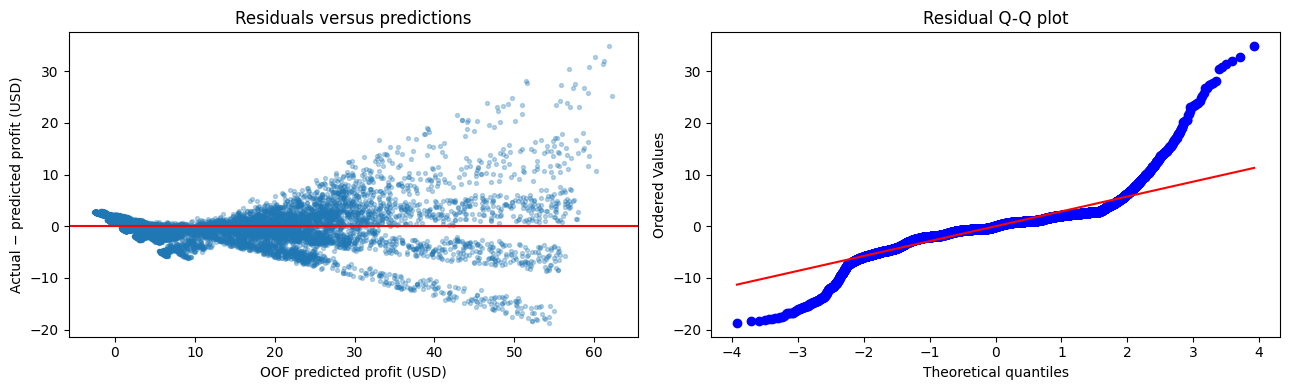

Mean residual USD: -0.0007
Negative OOF predictions: 2603


In [55]:
from scipy.stats import probplot

oof_predictions = cross_val_predict(
    best_reg_model,
    X,
    y_reg,
    cv=regression_cv,
    n_jobs=2
)

residuals = y_reg.to_numpy() - oof_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].scatter(
    oof_predictions,
    residuals,
    s=8,
    alpha=0.3
)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("OOF predicted profit (USD)")
axes[0].set_ylabel("Actual − predicted profit (USD)")
axes[0].set_title("Residuals versus predictions")

probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Residual Q-Q plot")

plt.tight_layout()
plt.savefig("04_residual_diagnostics.png", dpi=150)
plt.show()

print("Mean residual USD:", round(residuals.mean(), 4))
print(
    "Negative OOF predictions:",
    int((oof_predictions < 0).sum())
)

oof_diagnostics = pd.DataFrame({
    "device_id": train_df["device_id"],
    "actual_profit_usd": y_reg,
    "oof_predicted_profit_usd": oof_predictions,
    "residual_usd": residuals,
    "absolute_error_usd": np.abs(residuals)
})

oof_diagnostics.to_csv(
    "04_training_oof_diagnostics.csv",
    index=False
)

The mean out-of-fold residual was approximately −0.0007 USD, indicating little overall average bias. However, the residual plot showed increasing error spread with predicted profit, suggesting heteroscedasticity. The Q-Q plot showed substantial tail departures from normality. Additionally, 2,603 of 16,000 out-of-fold predictions (16.27%) were negative despite positive recorded targets. These findings support retaining Linear Regression as a benchmark while comparing nonlinear alternatives. Negative predictions were not automatically clipped.

Results

In [56]:
model_summary = {
    "notebook": "04_Linear_Regression_Logistic_Regression",
    "regression_model": "LinearRegression",
    "classification_model": "LogisticRegression",
    "regression_feature_set": best_reg_feature_set,
    "classification_feature_set": best_cls_feature_set,
    "regression_features": feature_sets[best_reg_feature_set],
    "classification_features": feature_sets[best_cls_feature_set],
    "regression_cv_mae_usd": float(-best_reg_search.best_score_),
    "classification_cv_macro_f1": float(best_cls_search.best_score_),
    "classification_parameters": best_cls_search.best_params_,
    "test_evaluated": False,
    "priority_meaning": "Profit-tier proxy",
    "sklearn_version": sklearn.__version__
}

with open("04_model_summary.json", "w") as file:
    json.dump(model_summary, file, indent=2)

joblib.dump(
    best_reg_model,
    "04_linear_profit_pipeline.joblib"
)

joblib.dump(
    best_cls_model,
    "04_logistic_priority_pipeline.joblib"
)

print("Baseline models and CV evidence saved.")
print("Test evaluation has not been performed.")

Baseline models and CV evidence saved.
Test evaluation has not been performed.


## Baseline interpretation

### Regression
- Selected feature set:
- Mean CV MAE:
- Mean CV RMSE:
- Mean CV R²:
- Improvement over the median dummy:
- Residual patterns:
- Negative prediction count:

### Classification
- Selected feature set:
- Selected C and class weighting:
- Mean CV macro-F1:
- Mean CV balanced accuracy:
- Improvement over the most-frequent dummy:

### Limitations
- CV scores were used for model selection.
- Priority labels are derived profit tiers.
- Classifier CV is conditional on thresholds learned from
  the full training targets.
- Metal-yield availability before the decision needs confirmation.
- Final test evaluation is pending.

### AI-use declaration
Describe the AI assistance actually used, the code/results
verified by the student, and the student's own contribution.

In [57]:
train_df.to_csv("04_train_features.csv", index=False)
test_df.to_csv("04_test_features.csv", index=False)


# 05 — Decision Tree Models

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Regression: DecisionTreeRegressor
Classification: DecisionTreeClassifier

Decision trees can capture nonlinear relationships and feature
interactions. Tree depth and minimum leaf size are tuned to
control overfitting.

Validation:
- Preserve the existing train/test split.
- Use the same five-fold settings as Notebook 04.
- Fit preprocessing inside each CV training fold.
- Compare raw-only and engineered feature sets.
- Keep the test dataset untouched during model selection.

Batch_Priority represents derived profit tiers.

Libraries import

In [58]:
import pandas as pd
import numpy as np
import json
import joblib
import platform
import sklearn

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import (
    DecisionTreeRegressor,
    DecisionTreeClassifier
)

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    GridSearchCV
)

pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
scikit-learn: 1.6.1


In [59]:
required_files = [
    "train_features.csv",
    "test_features.csv",
    "feature_config.json"
]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

with open("feature_config.json") as file:
    config = json.load(file)

print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (16000, 19)
Test dataset: (4000, 19)


Inputs and labels validation

In [60]:
for dataset in [train_df, test_df]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

assert len(train_df) == 16000
assert len(test_df) == 4000

all_features = config["feature_columns"]
raw_features = config["raw_feature_columns"]

forbidden_inputs = {
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
}

assert not set(all_features) & forbidden_inputs

X = train_df[all_features].copy()
y_reg = train_df["total_profit_usd"].copy()
y_cls = train_df["Batch_Priority"].copy()

assert np.isfinite(y_reg).all()
assert y_cls.notna().all()
assert set(y_cls.unique()) == {"Low", "Medium", "High"}

policy = config["priority_policy"]

expected_labels = np.where(
    y_reg <= policy["low_cutoff_usd"],
    "Low",
    np.where(
        y_reg <= policy["high_cutoff_usd"],
        "Medium",
        "High"
    )
)

assert np.array_equal(
    y_cls.to_numpy(),
    expected_labels
)

print("Consistency checks passed.")
print("Training inputs:", X.shape)

Consistency checks passed.
Training inputs: (16000, 15)


Tree preprocessing pipeline

In [61]:
def make_tree_pipeline(model, selected_features):
    numeric = [
        column
        for column in config["numeric_features"]
        if column in selected_features
    ]

    categorical = [
        column
        for column in config["categorical_features"]
        if column in selected_features
    ]

    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

Create CV folds

In [62]:
regression_cv = list(
    KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_reg)
)

classification_cv = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_cls)
)

feature_sets = {
    "raw_only": raw_features,
    "with_engineered": all_features
}

print("Five-fold CV configured.")

Five-fold CV configured.


Decision Tree Regression tune

In [63]:
regression_grid = {
    "model__max_depth": [6, 12, None],
    "model__min_samples_leaf": [2, 10, 30]
}

regression_searches = {}
regression_rows = []

for name, selected_features in feature_sets.items():
    pipeline = make_tree_pipeline(
        DecisionTreeRegressor(random_state=42),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=regression_grid,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        refit="mae",
        cv=regression_cv,
        n_jobs=2,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(X, y_reg)
    regression_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    regression_rows.append({
        "feature_set": name,
        "CV_MAE_USD": -results["mean_test_mae"][index],
        "CV_MAE_STD": results["std_test_mae"][index],
        "CV_RMSE_USD": -results["mean_test_rmse"][index],
        "CV_R2": results["mean_test_r2"][index],
        "Train_MAE_USD": -results["mean_train_mae"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"05_regression_candidates_{name}.csv",
        index=False
    )

regression_comparison = pd.DataFrame(
    regression_rows
).sort_values("CV_MAE_USD")

display(regression_comparison)

best_reg_feature_set = (
    regression_comparison.iloc[0]["feature_set"]
)

best_reg_search = regression_searches[
    best_reg_feature_set
]

best_reg_model = best_reg_search.best_estimator_

print("Selected regression features:", best_reg_feature_set)
print("Selected parameters:", best_reg_search.best_params_)

,feature_set,CV_MAE_USD,CV_MAE_STD,CV_RMSE_USD,CV_R2,Train_MAE_USD,best_parameters
0,raw_only,0.339261,0.007714,0.761429,0.996539,0.254431,"{""model__max_depth"": null, ""model__min_samples..."
1,with_engineered,0.341849,0.007132,0.764515,0.996512,0.252396,"{""model__max_depth"": null, ""model__min_samples..."


Selected regression features: raw_only
Selected parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10}


Tune Decision Treen Classification

In [64]:
classification_grid = {
    "model__max_depth": [6, 12, None],
    "model__min_samples_leaf": [2, 10, 30],
    "model__class_weight": [None, "balanced"]
}

classification_searches = {}
classification_rows = []

for name, selected_features in feature_sets.items():
    pipeline = make_tree_pipeline(
        DecisionTreeClassifier(random_state=42),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=classification_grid,
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        refit="macro_f1",
        cv=classification_cv,
        n_jobs=2,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(X, y_cls)
    classification_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    classification_rows.append({
        "feature_set": name,
        "CV_Macro_F1": results["mean_test_macro_f1"][index],
        "CV_Macro_F1_STD": results["std_test_macro_f1"][index],
        "CV_Balanced_Accuracy": (
            results["mean_test_balanced_accuracy"][index]
        ),
        "CV_Accuracy": results["mean_test_accuracy"][index],
        "Train_Macro_F1": results["mean_train_macro_f1"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"05_classification_candidates_{name}.csv",
        index=False
    )

classification_comparison = pd.DataFrame(
    classification_rows
).sort_values("CV_Macro_F1", ascending=False)

display(classification_comparison)

best_cls_feature_set = (
    classification_comparison.iloc[0]["feature_set"]
)

best_cls_search = classification_searches[
    best_cls_feature_set
]

best_cls_model = best_cls_search.best_estimator_

print("Selected classification features:", best_cls_feature_set)
print("Selected parameters:", best_cls_search.best_params_)

,feature_set,CV_Macro_F1,CV_Macro_F1_STD,CV_Balanced_Accuracy,CV_Accuracy,Train_Macro_F1,best_parameters
1,with_engineered,0.978937,0.001988,0.978936,0.978938,0.987460,"{""model__class_weight"": ""balanced"", ""model__ma..."
0,raw_only,0.978321,0.001597,0.978311,0.978313,0.986978,"{""model__class_weight"": ""balanced"", ""model__ma..."


Selected classification features: with_engineered
Selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': 12, 'model__min_samples_leaf': 10}


Fold Results

In [65]:
reg_results = best_reg_search.cv_results_
reg_index = best_reg_search.best_index_

regression_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE_USD": [
        -reg_results[f"split{i}_test_mae"][reg_index]
        for i in range(5)
    ],
    "RMSE_USD": [
        -reg_results[f"split{i}_test_rmse"][reg_index]
        for i in range(5)
    ],
    "R2": [
        reg_results[f"split{i}_test_r2"][reg_index]
        for i in range(5)
    ]
})

cls_results = best_cls_search.cv_results_
cls_index = best_cls_search.best_index_

classification_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Macro_F1": [
        cls_results[f"split{i}_test_macro_f1"][cls_index]
        for i in range(5)
    ],
    "Balanced_Accuracy": [
        cls_results[f"split{i}_test_balanced_accuracy"][cls_index]
        for i in range(5)
    ],
    "Accuracy": [
        cls_results[f"split{i}_test_accuracy"][cls_index]
        for i in range(5)
    ]
})

display(regression_fold_results)
display(classification_fold_results)

,Fold,MAE_USD,RMSE_USD,R2
0,1,0.338948,0.776009,0.996541
1,2,0.330263,0.758952,0.996526
2,3,0.350592,0.835463,0.995804
3,4,0.331692,0.691308,0.997036
4,5,0.344809,0.745414,0.996791


,Fold,Macro_F1,Balanced_Accuracy,Accuracy
0,1,0.979683,0.979691,0.979688
1,2,0.981559,0.981562,0.981563
2,3,0.975921,0.975933,0.975938
3,4,0.977502,0.977494,0.977500
4,5,0.980022,0.979998,0.980000


overfitting indicators

In [66]:
reg_train_mae = -reg_results[
    "mean_train_mae"
][reg_index]

reg_cv_mae = -reg_results[
    "mean_test_mae"
][reg_index]

cls_train_f1 = cls_results[
    "mean_train_macro_f1"
][cls_index]

cls_cv_f1 = cls_results[
    "mean_test_macro_f1"
][cls_index]

overfitting_summary = pd.DataFrame([
    {
        "task": "Regression",
        "metric": "MAE USD",
        "training_score": reg_train_mae,
        "cv_score": reg_cv_mae,
        "gap": reg_cv_mae - reg_train_mae
    },
    {
        "task": "Classification",
        "metric": "Macro-F1",
        "training_score": cls_train_f1,
        "cv_score": cls_cv_f1,
        "gap": cls_train_f1 - cls_cv_f1
    }
])

display(overfitting_summary)

print(
    "Selected regression tree depth:",
    best_reg_model.named_steps["model"].get_depth()
)

print(
    "Selected classification tree depth:",
    best_cls_model.named_steps["model"].get_depth()
)

,task,metric,training_score,cv_score,gap
0,Regression,MAE USD,0.254431,0.339261,0.084830
1,Classification,Macro-F1,0.987460,0.978937,0.008523


Selected regression tree depth: 22
Selected classification tree depth: 12


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Decision Tree Regression achieved a mean CV MAE of USD 0.339261, approximately 82.9% lower than the Linear Regression baseline. Its training MAE was USD 0.254431, giving a train–CV gap of USD 0.084830. Decision Tree Classification achieved a CV macro-F1 of 0.978937, slightly above the Logistic Regression baseline, with a train–CV gap of 0.008523. The fitted regression and classification trees had depths of 22 and 12 respectively. These results support retaining both trees as candidates; final model selection and held-out test evaluation remain pending.

Baseline comparison (summery)

In [67]:
model_summary = {
    "notebook": "05_Decision_Tree_Models",
    "regression_model": "DecisionTreeRegressor",
    "classification_model": "DecisionTreeClassifier",

    "regression_feature_set": best_reg_feature_set,
    "classification_feature_set": best_cls_feature_set,

    "regression_features": feature_sets[best_reg_feature_set],
    "classification_features": feature_sets[best_cls_feature_set],

    "regression_cv_mae_usd": float(
        -best_reg_search.best_score_
    ),
    "regression_cv_rmse_usd": float(
        -reg_results["mean_test_rmse"][reg_index]
    ),
    "regression_cv_r2": float(
        reg_results["mean_test_r2"][reg_index]
    ),

    "classification_cv_macro_f1": float(
        best_cls_search.best_score_
    ),
    "classification_cv_balanced_accuracy": float(
        cls_results["mean_test_balanced_accuracy"][cls_index]
    ),
    "classification_cv_accuracy": float(
        cls_results["mean_test_accuracy"][cls_index]
    ),

    "regression_parameters": best_reg_search.best_params_,
    "classification_parameters": best_cls_search.best_params_,

    "test_evaluated": False,
    "priority_meaning": "Profit-tier proxy",
    "sklearn_version": sklearn.__version__
}

display(pd.DataFrame([model_summary]))

,notebook,regression_model,classification_model,regression_feature_set,classification_feature_set,regression_features,classification_features,regression_cv_mae_usd,regression_cv_rmse_usd,regression_cv_r2,classification_cv_macro_f1,classification_cv_balanced_accuracy,classification_cv_accuracy,regression_parameters,classification_parameters,test_evaluated,priority_meaning,sklearn_version
0,05_Decision_Tree_Models,DecisionTreeRegressor,DecisionTreeClassifier,raw_only,with_engineered,"[weight_g, device_age_years, gold_yield_g, sil...","[weight_g, device_age_years, gold_yield_g, sil...",0.339261,0.761429,0.996539,0.978937,0.978936,0.978938,"{'model__max_depth': None, 'model__min_samples...","{'model__class_weight': 'balanced', 'model__ma...",False,Profit-tier proxy,1.6.1


Models and evidace save

In [68]:
regression_comparison.to_csv(
    "05_regression_feature_comparison.csv",
    index=False
)

classification_comparison.to_csv(
    "05_classification_feature_comparison.csv",
    index=False
)

regression_fold_results.to_csv(
    "05_regression_cv_folds.csv",
    index=False
)

classification_fold_results.to_csv(
    "05_classification_cv_folds.csv",
    index=False
)

overfitting_summary.to_csv(
    "05_overfitting_summary.csv",
    index=False
)

with open("05_model_summary.json", "w") as file:
    json.dump(model_summary, file, indent=2)

joblib.dump(
    best_reg_model,
    "05_tree_profit_pipeline.joblib"
)

joblib.dump(
    best_cls_model,
    "05_tree_priority_pipeline.joblib"
)

print("Decision Tree models and CV evidence saved.")
print("Test evaluation has not been performed.")

Decision Tree models and CV evidence saved.
Test evaluation has not been performed.


## Decision Tree interpretation

### Regression
- Selected feature set:
- Selected depth and minimum leaf size:
- Mean CV MAE, RMSE and R²:
- Comparison with Linear Regression:
- Training/CV performance gap:

### Classification
- Selected feature set:
- Selected depth, minimum leaf size and class weighting:
- Mean CV macro-F1 and balanced accuracy:
- Comparison with Logistic Regression:
- Training/CV performance gap:

### Limitations
- CV results were used for tuning and feature selection.
- Final test evaluation is pending.
- A single tree can be sensitive to changes in training data.
- Priority labels are derived profit tiers.
- Classifier CV is conditional on the training-derived tier policy.

### AI-use declaration
Record the assistance actually used and the student's own
verification, interpretation and contribution.

In [69]:
train_df.to_csv("05_train_features.csv", index=False)
test_df.to_csv("05_test_features.csv", index=False)


# 06 — Random Forest Models

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Regression: RandomForestRegressor
Classification: RandomForestClassifier

Random Forest combines multiple trees to reduce the variance
associated with a single decision tree.

Validation:
- Preserve the existing train/test split.
- Use the same five-fold settings as previous notebooks.
- Fit preprocessing inside each CV training fold.
- Compare raw-only and engineered feature sets.
- Keep test evaluation pending until model selection is recorded.

Batch_Priority represents derived profit tiers.

Import libraries

In [70]:
import pandas as pd
import numpy as np
import json
import joblib
import platform
import sklearn

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    GridSearchCV
)

pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
scikit-learn: 1.6.1


In [71]:
required_files = [
    "train_features.csv",
    "test_features.csv",
    "feature_config.json"
]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

with open("feature_config.json") as file:
    config = json.load(file)

print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (16000, 19)
Test dataset: (4000, 19)


Input and lable validate

In [72]:
for dataset in [train_df, test_df]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

assert len(train_df) == 16000
assert len(test_df) == 4000

all_features = config["feature_columns"]
raw_features = config["raw_feature_columns"]

forbidden_inputs = {
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
}

assert not set(all_features) & forbidden_inputs

X = train_df[all_features].copy()
y_reg = train_df["total_profit_usd"].copy()
y_cls = train_df["Batch_Priority"].copy()

assert np.isfinite(y_reg).all()
assert y_cls.notna().all()
assert set(y_cls.unique()) == {"Low", "Medium", "High"}

policy = config["priority_policy"]

expected_labels = np.where(
    y_reg <= policy["low_cutoff_usd"],
    "Low",
    np.where(
        y_reg <= policy["high_cutoff_usd"],
        "Medium",
        "High"
    )
)

assert np.array_equal(
    y_cls.to_numpy(),
    expected_labels
)

print("Consistency checks passed.")
print("Training inputs:", X.shape)

Consistency checks passed.
Training inputs: (16000, 15)


Preprocessing pipeline

In [73]:
def make_forest_pipeline(model, selected_features):
    numeric = [
        column
        for column in config["numeric_features"]
        if column in selected_features
    ]

    categorical = [
        column
        for column in config["categorical_features"]
        if column in selected_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

CV folds and feature sets

In [74]:
regression_cv = list(
    KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_reg)
)

classification_cv = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_cls)
)

feature_sets = {
    "raw_only": raw_features,
    "with_engineered": all_features
}

print("Five-fold CV configured.")

Five-fold CV configured.


Tuning Regression

In [75]:
regression_grid = {
    "model__max_depth": [12, None],
    "model__min_samples_leaf": [2, 10]
}

regression_searches = {}
regression_rows = []

for name, selected_features in feature_sets.items():
    print("Running regression:", name)

    pipeline = make_forest_pipeline(
        RandomForestRegressor(
            n_estimators=100,
            max_features=1.0,
            random_state=42,
            n_jobs=1
        ),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=regression_grid,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        refit="mae",
        cv=regression_cv,
        n_jobs=2,
        pre_dispatch=2,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    search.fit(X, y_reg)
    regression_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    regression_rows.append({
        "feature_set": name,
        "CV_MAE_USD": -results["mean_test_mae"][index],
        "CV_MAE_STD": results["std_test_mae"][index],
        "CV_RMSE_USD": -results["mean_test_rmse"][index],
        "CV_R2": results["mean_test_r2"][index],
        "Train_MAE_USD": -results["mean_train_mae"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"06_regression_candidates_{name}.csv",
        index=False
    )

regression_comparison = pd.DataFrame(
    regression_rows
).sort_values("CV_MAE_USD")

display(regression_comparison)

best_reg_feature_set = (
    regression_comparison.iloc[0]["feature_set"]
)

best_reg_search = regression_searches[
    best_reg_feature_set
]

best_reg_model = best_reg_search.best_estimator_

print("Selected regression features:", best_reg_feature_set)
print("Selected parameters:", best_reg_search.best_params_)

Running regression: raw_only
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running regression: with_engineered
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,feature_set,CV_MAE_USD,CV_MAE_STD,CV_RMSE_USD,CV_R2,Train_MAE_USD,best_parameters
0,raw_only,0.279303,0.003596,0.583801,0.997970,0.124545,"{""model__max_depth"": null, ""model__min_samples..."
1,with_engineered,0.280485,0.003476,0.585469,0.997959,0.122802,"{""model__max_depth"": null, ""model__min_samples..."


Selected regression features: raw_only
Selected parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}


Classification Tuning

In [76]:
classification_grid = {
    "model__max_depth": [12, None],
    "model__min_samples_leaf": [2, 10],
    "model__class_weight": [None, "balanced"]
}

classification_searches = {}
classification_rows = []

for name, selected_features in feature_sets.items():
    print("Running classification:", name)

    pipeline = make_forest_pipeline(
        RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            random_state=42,
            n_jobs=1
        ),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=classification_grid,
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        refit="macro_f1",
        cv=classification_cv,
        n_jobs=2,
        pre_dispatch=2,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    search.fit(X, y_cls)
    classification_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    classification_rows.append({
        "feature_set": name,
        "CV_Macro_F1": results["mean_test_macro_f1"][index],
        "CV_Macro_F1_STD": results["std_test_macro_f1"][index],
        "CV_Balanced_Accuracy": (
            results["mean_test_balanced_accuracy"][index]
        ),
        "CV_Accuracy": results["mean_test_accuracy"][index],
        "Train_Macro_F1": results["mean_train_macro_f1"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"06_classification_candidates_{name}.csv",
        index=False
    )

classification_comparison = pd.DataFrame(
    classification_rows
).sort_values("CV_Macro_F1", ascending=False)

display(classification_comparison)

best_cls_feature_set = (
    classification_comparison.iloc[0]["feature_set"]
)

best_cls_search = classification_searches[
    best_cls_feature_set
]

best_cls_model = best_cls_search.best_estimator_

print("Selected classification features:", best_cls_feature_set)
print("Selected parameters:", best_cls_search.best_params_)

Running classification: raw_only
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Running classification: with_engineered
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,feature_set,CV_Macro_F1,CV_Macro_F1_STD,CV_Balanced_Accuracy,CV_Accuracy,Train_Macro_F1,best_parameters
0,raw_only,0.979871,0.003366,0.979872,0.979875,0.997360,"{""model__class_weight"": ""balanced"", ""model__ma..."
1,with_engineered,0.979063,0.002640,0.979059,0.979063,0.998188,"{""model__class_weight"": ""balanced"", ""model__ma..."


Selected classification features: raw_only
Selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}


Fold results

In [77]:
reg_results = best_reg_search.cv_results_
reg_index = best_reg_search.best_index_

regression_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE_USD": [
        -reg_results[f"split{i}_test_mae"][reg_index]
        for i in range(5)
    ],
    "RMSE_USD": [
        -reg_results[f"split{i}_test_rmse"][reg_index]
        for i in range(5)
    ],
    "R2": [
        reg_results[f"split{i}_test_r2"][reg_index]
        for i in range(5)
    ]
})

cls_results = best_cls_search.cv_results_
cls_index = best_cls_search.best_index_

classification_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Macro_F1": [
        cls_results[f"split{i}_test_macro_f1"][cls_index]
        for i in range(5)
    ],
    "Balanced_Accuracy": [
        cls_results[f"split{i}_test_balanced_accuracy"][cls_index]
        for i in range(5)
    ],
    "Accuracy": [
        cls_results[f"split{i}_test_accuracy"][cls_index]
        for i in range(5)
    ]
})

display(regression_fold_results)
display(classification_fold_results)

,Fold,MAE_USD,RMSE_USD,R2
0,1,0.275895,0.583030,0.998048
1,2,0.282627,0.590207,0.997899
2,3,0.274041,0.596474,0.997861
3,4,0.282060,0.576374,0.997939
4,5,0.281892,0.572921,0.998104


,Fold,Macro_F1,Balanced_Accuracy,Accuracy
0,1,0.976247,0.976250,0.976250
1,2,0.982192,0.982189,0.982187
2,3,0.975300,0.975308,0.975313
3,4,0.982813,0.982809,0.982812
4,5,0.982801,0.982805,0.982812


Training/CV

In [78]:
reg_train_mae = -reg_results[
    "mean_train_mae"
][reg_index]

reg_cv_mae = -reg_results[
    "mean_test_mae"
][reg_index]

cls_train_f1 = cls_results[
    "mean_train_macro_f1"
][cls_index]

cls_cv_f1 = cls_results[
    "mean_test_macro_f1"
][cls_index]

overfitting_summary = pd.DataFrame([
    {
        "task": "Regression",
        "metric": "MAE USD",
        "training_score": reg_train_mae,
        "cv_score": reg_cv_mae,
        "gap": reg_cv_mae - reg_train_mae
    },
    {
        "task": "Classification",
        "metric": "Macro-F1",
        "training_score": cls_train_f1,
        "cv_score": cls_cv_f1,
        "gap": cls_train_f1 - cls_cv_f1
    }
])

display(overfitting_summary)

,task,metric,training_score,cv_score,gap
0,Regression,MAE USD,0.124545,0.279303,0.154758
1,Classification,Macro-F1,0.997360,0.979871,0.017489


Model summary

In [79]:
model_summary = {
    "notebook": "06_Random_Forest_Models",
    "regression_model": "RandomForestRegressor",
    "classification_model": "RandomForestClassifier",

    "regression_feature_set": best_reg_feature_set,
    "classification_feature_set": best_cls_feature_set,

    "regression_features": feature_sets[best_reg_feature_set],
    "classification_features": feature_sets[best_cls_feature_set],

    "regression_cv_mae_usd": float(
        -best_reg_search.best_score_
    ),
    "regression_cv_rmse_usd": float(
        -reg_results["mean_test_rmse"][reg_index]
    ),
    "regression_cv_r2": float(
        reg_results["mean_test_r2"][reg_index]
    ),

    "classification_cv_macro_f1": float(
        best_cls_search.best_score_
    ),
    "classification_cv_balanced_accuracy": float(
        cls_results["mean_test_balanced_accuracy"][cls_index]
    ),
    "classification_cv_accuracy": float(
        cls_results["mean_test_accuracy"][cls_index]
    ),

    "regression_parameters": {
        **best_reg_search.best_params_,
        "model__n_estimators": 100,
        "model__max_features": 1.0
    },

    "classification_parameters": {
        **best_cls_search.best_params_,
        "model__n_estimators": 100,
        "model__max_features": "sqrt"
    },

    "random_state": 42,
    "test_evaluated": False,
    "priority_meaning": "Profit-tier proxy",
    "sklearn_version": sklearn.__version__
}

display(pd.DataFrame([model_summary]))

,notebook,regression_model,classification_model,regression_feature_set,classification_feature_set,regression_features,classification_features,regression_cv_mae_usd,regression_cv_rmse_usd,regression_cv_r2,classification_cv_macro_f1,classification_cv_balanced_accuracy,classification_cv_accuracy,regression_parameters,classification_parameters,random_state,test_evaluated,priority_meaning,sklearn_version
0,06_Random_Forest_Models,RandomForestRegressor,RandomForestClassifier,raw_only,raw_only,"[weight_g, device_age_years, gold_yield_g, sil...","[weight_g, device_age_years, gold_yield_g, sil...",0.279303,0.583801,0.99797,0.979871,0.979872,0.979875,"{'model__max_depth': None, 'model__min_samples...","{'model__class_weight': 'balanced', 'model__ma...",42,False,Profit-tier proxy,1.6.1


Model and evidace save

In [80]:
regression_comparison.to_csv(
    "06_regression_feature_comparison.csv",
    index=False
)

classification_comparison.to_csv(
    "06_classification_feature_comparison.csv",
    index=False
)

regression_fold_results.to_csv(
    "06_regression_cv_folds.csv",
    index=False
)

classification_fold_results.to_csv(
    "06_classification_cv_folds.csv",
    index=False
)

overfitting_summary.to_csv(
    "06_overfitting_summary.csv",
    index=False
)

with open("06_model_summary.json", "w") as file:
    json.dump(model_summary, file, indent=2)

joblib.dump(
    best_reg_model,
    "06_forest_profit_pipeline.joblib"
)

joblib.dump(
    best_cls_model,
    "06_forest_priority_pipeline.joblib"
)

print("Random Forest models and CV evidence saved.")
print("Test evaluation has not been performed.")

Random Forest models and CV evidence saved.
Test evaluation has not been performed.


Interpretation Text cell

## Random Forest interpretation

### Regression
- Selected feature set:
- Selected depth and minimum leaf size:
- Mean CV MAE, RMSE and R²:
- Comparison with Linear Regression and Decision Tree:
- Training/CV gap:

### Classification
- Selected feature set:
- Selected depth, minimum leaf size and class weighting:
- Mean CV macro-F1 and balanced accuracy:
- Comparison with Logistic Regression and Decision Tree:
- Training/CV gap:

### Limitations
- CV results were used for tuning and feature selection.
- Only a limited hyperparameter grid was evaluated.
- Forests require more computation and are harder to explain
  than a single tree.
- Priority labels are derived profit tiers.
- Classifier CV is conditional on the training-derived policy.
- Final held-out test evaluation remains pending.

### AI-use declaration
Record actual AI assistance, student verification and contribution.

In [81]:
train_df.to_csv("06_train_features.csv", index=False)
test_df.to_csv("06_test_features.csv", index=False)


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Random Forest using raw features achieved a mean CV MAE of USD 0.279303, RMSE of USD 0.583801, and R² of 0.997970. Its MAE was approximately 17.7% lower than Decision Tree Regression. Random Forest Classification achieved a CV macro-F1 of 0.979871, providing a small improvement over Decision Tree Classification. Both selected models used unlimited maximum depth and a minimum leaf size of two; the classifier used balanced class weights. Training–CV gaps indicate some overfitting, although CV performance improved. Final model selection and held-out test evaluation remain pending.

# 07 — Gradient Boosting Models

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Regression: GradientBoostingRegressor
Classification: GradientBoostingClassifier

Gradient Boosting builds trees sequentially, with later trees
improving the current ensemble's predictions.

Validation:
- Preserve the existing train/test split.
- Use the same five-fold settings as previous notebooks.
- Fit preprocessing inside each CV training fold.
- Compare raw-only and engineered feature sets.
- Keep test evaluation pending until model selection is recorded.

Batch_Priority represents derived profit tiers.

Import libraries

In [82]:
import pandas as pd
import numpy as np
import json
import joblib
import platform
import sklearn

from google.colab import files

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import (
    GradientBoostingRegressor,
    GradientBoostingClassifier
)

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    GridSearchCV
)

pd.set_option("display.max_columns", None)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
scikit-learn: 1.6.1


In [83]:
required_files = [
    "train_features.csv",
    "test_features.csv",
    "feature_config.json"
]

for filename in required_files:
    assert Path(filename).is_file(), f"Missing generated file: {filename}"

train_df = pd.read_csv("train_features.csv")
test_df = pd.read_csv("test_features.csv")

with open("feature_config.json") as file:
    config = json.load(file)

print("Training dataset:", train_df.shape)
print("Test dataset:", test_df.shape)

Training dataset: (16000, 19)
Test dataset: (4000, 19)


Validate inputs and target validate

In [84]:
for dataset in [train_df, test_df]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

assert len(train_df) == 16000
assert len(test_df) == 4000

all_features = config["feature_columns"]
raw_features = config["raw_feature_columns"]

forbidden_inputs = {
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
}

assert not set(all_features) & forbidden_inputs

X = train_df[all_features].copy()
y_reg = train_df["total_profit_usd"].copy()
y_cls = train_df["Batch_Priority"].copy()

assert np.isfinite(y_reg).all()
assert y_cls.notna().all()
assert set(y_cls.unique()) == {"Low", "Medium", "High"}

policy = config["priority_policy"]

expected_labels = np.where(
    y_reg <= policy["low_cutoff_usd"],
    "Low",
    np.where(
        y_reg <= policy["high_cutoff_usd"],
        "Medium",
        "High"
    )
)

assert np.array_equal(
    y_cls.to_numpy(),
    expected_labels
)

print("Consistency checks passed.")
print("Training inputs:", X.shape)

Consistency checks passed.
Training inputs: (16000, 15)


Preprocessing pipeline

In [85]:
def make_boosting_pipeline(model, selected_features):
    numeric = [
        column
        for column in config["numeric_features"]
        if column in selected_features
    ]

    categorical = [
        column
        for column in config["categorical_features"]
        if column in selected_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

create cv folders

In [86]:
regression_cv = list(
    KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_reg)
)

classification_cv = list(
    StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y_cls)
)

feature_sets = {
    "raw_only": raw_features,
    "with_engineered": all_features
}

print("Five-fold CV configured.")

Five-fold CV configured.


Regression tune

In [87]:
regression_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3]
}

regression_searches = {}
regression_rows = []

for name, selected_features in feature_sets.items():
    print("Running regression:", name)

    pipeline = make_boosting_pipeline(
        GradientBoostingRegressor(
            learning_rate=0.1,
            min_samples_leaf=5,
            random_state=42
        ),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=regression_grid,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        refit="mae",
        cv=regression_cv,
        n_jobs=2,
        pre_dispatch=2,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    search.fit(X, y_reg)
    regression_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    regression_rows.append({
        "feature_set": name,
        "CV_MAE_USD": -results["mean_test_mae"][index],
        "CV_MAE_STD": results["std_test_mae"][index],
        "CV_RMSE_USD": -results["mean_test_rmse"][index],
        "CV_R2": results["mean_test_r2"][index],
        "Train_MAE_USD": -results["mean_train_mae"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"07_regression_candidates_{name}.csv",
        index=False
    )

regression_comparison = pd.DataFrame(
    regression_rows
).sort_values("CV_MAE_USD")

display(regression_comparison)

best_reg_feature_set = (
    regression_comparison.iloc[0]["feature_set"]
)

best_reg_search = regression_searches[
    best_reg_feature_set
]

best_reg_model = best_reg_search.best_estimator_

print("Selected regression features:", best_reg_feature_set)
print("Selected parameters:", best_reg_search.best_params_)

Running regression: raw_only
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running regression: with_engineered
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,feature_set,CV_MAE_USD,CV_MAE_STD,CV_RMSE_USD,CV_R2,Train_MAE_USD,best_parameters
0,raw_only,0.331479,0.006211,0.613501,0.997758,0.299424,"{""model__max_depth"": 3, ""model__n_estimators"":..."
1,with_engineered,0.339311,0.005821,0.621837,0.997695,0.302788,"{""model__max_depth"": 3, ""model__n_estimators"":..."


Selected regression features: raw_only
Selected parameters: {'model__max_depth': 3, 'model__n_estimators': 200}


Classification tune

In [89]:
classification_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3]
}

classification_searches = {}
classification_rows = []

for name, selected_features in feature_sets.items():
    print("Running classification:", name)

    pipeline = make_boosting_pipeline(
        GradientBoostingClassifier(
            learning_rate=0.1,
            min_samples_leaf=5,
            random_state=42
        ),
        selected_features
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=classification_grid,
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        refit="macro_f1",
        cv=classification_cv,
        n_jobs=2,
        pre_dispatch=2,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    search.fit(X, y_cls)
    classification_searches[name] = search

    results = search.cv_results_
    index = search.best_index_

    classification_rows.append({
        "feature_set": name,
        "CV_Macro_F1": results["mean_test_macro_f1"][index],
        "CV_Macro_F1_STD": results["std_test_macro_f1"][index],
        "CV_Balanced_Accuracy": (
            results["mean_test_balanced_accuracy"][index]
        ),
        "CV_Accuracy": results["mean_test_accuracy"][index],
        "Train_Macro_F1": results["mean_train_macro_f1"][index],
        "best_parameters": json.dumps(search.best_params_)
    })

    pd.DataFrame(results).to_csv(
        f"07_classification_candidates_{name}.csv",
        index=False
    )

classification_comparison = pd.DataFrame(
    classification_rows
).sort_values("CV_Macro_F1", ascending=False)

display(classification_comparison)

best_cls_feature_set = (
    classification_comparison.iloc[0]["feature_set"]
)

best_cls_search = classification_searches[
    best_cls_feature_set
]

best_cls_model = best_cls_search.best_estimator_

print("Selected classification features:", best_cls_feature_set)
print("Selected parameters:", best_cls_search.best_params_)

Running classification: raw_only
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running classification: with_engineered
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,feature_set,CV_Macro_F1,CV_Macro_F1_STD,CV_Balanced_Accuracy,CV_Accuracy,Train_Macro_F1,best_parameters
0,raw_only,0.982945,0.002168,0.982936,0.982938,0.994235,"{""model__max_depth"": 3, ""model__n_estimators"":..."
1,with_engineered,0.982070,0.002304,0.982060,0.982062,0.994735,"{""model__max_depth"": 3, ""model__n_estimators"":..."


Selected classification features: raw_only
Selected parameters: {'model__max_depth': 3, 'model__n_estimators': 200}


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Gradient Boosting Classification using raw features achieved a mean five-fold CV macro-F1 of 0.982945, balanced accuracy of 0.982936, and accuracy of 98.2938%. The selected configuration used 200 boosting stages and a maximum tree depth of three. Its training–CV macro-F1 gap was 0.011290. It achieved the highest mean CV macro-F1 among the four evaluated classifier families, making it the leading classification candidate. These results concern derived profit tiers; held-out test evaluation remains pending.

Fold results

In [90]:
reg_results = best_reg_search.cv_results_
reg_index = best_reg_search.best_index_

regression_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE_USD": [
        -reg_results[f"split{i}_test_mae"][reg_index]
        for i in range(5)
    ],
    "RMSE_USD": [
        -reg_results[f"split{i}_test_rmse"][reg_index]
        for i in range(5)
    ],
    "R2": [
        reg_results[f"split{i}_test_r2"][reg_index]
        for i in range(5)
    ]
})

cls_results = best_cls_search.cv_results_
cls_index = best_cls_search.best_index_

classification_fold_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Macro_F1": [
        cls_results[f"split{i}_test_macro_f1"][cls_index]
        for i in range(5)
    ],
    "Balanced_Accuracy": [
        cls_results[f"split{i}_test_balanced_accuracy"][cls_index]
        for i in range(5)
    ],
    "Accuracy": [
        cls_results[f"split{i}_test_accuracy"][cls_index]
        for i in range(5)
    ]
})

display(regression_fold_results)
display(classification_fold_results)

,Fold,MAE_USD,RMSE_USD,R2
0,1,0.328466,0.609983,0.997863
1,2,0.338649,0.628345,0.997619
2,3,0.338419,0.632593,0.997594
3,4,0.322568,0.596777,0.997791
4,5,0.329291,0.599809,0.997922


,Fold,Macro_F1,Balanced_Accuracy,Accuracy
0,1,0.984404,0.984378,0.984375
1,2,0.983751,0.983750,0.983750
2,3,0.978746,0.978746,0.978750
3,4,0.984694,0.984685,0.984688
4,5,0.983130,0.983119,0.983125


Training CV/Gap

In [91]:
reg_train_mae = -reg_results[
    "mean_train_mae"
][reg_index]

reg_cv_mae = -reg_results[
    "mean_test_mae"
][reg_index]

cls_train_f1 = cls_results[
    "mean_train_macro_f1"
][cls_index]

cls_cv_f1 = cls_results[
    "mean_test_macro_f1"
][cls_index]

overfitting_summary = pd.DataFrame([
    {
        "task": "Regression",
        "metric": "MAE USD",
        "training_score": reg_train_mae,
        "cv_score": reg_cv_mae,
        "gap": reg_cv_mae - reg_train_mae
    },
    {
        "task": "Classification",
        "metric": "Macro-F1",
        "training_score": cls_train_f1,
        "cv_score": cls_cv_f1,
        "gap": cls_train_f1 - cls_cv_f1
    }
])

display(overfitting_summary)

,task,metric,training_score,cv_score,gap
0,Regression,MAE USD,0.299424,0.331479,0.032054
1,Classification,Macro-F1,0.994235,0.982945,0.011290


Model summary

In [92]:
model_summary = {
    "notebook": "07_Gradient_Boosting_Models",
    "regression_model": "GradientBoostingRegressor",
    "classification_model": "GradientBoostingClassifier",

    "regression_feature_set": best_reg_feature_set,
    "classification_feature_set": best_cls_feature_set,

    "regression_features": feature_sets[best_reg_feature_set],
    "classification_features": feature_sets[best_cls_feature_set],

    "regression_cv_mae_usd": float(
        -best_reg_search.best_score_
    ),
    "regression_cv_rmse_usd": float(
        -reg_results["mean_test_rmse"][reg_index]
    ),
    "regression_cv_r2": float(
        reg_results["mean_test_r2"][reg_index]
    ),

    "classification_cv_macro_f1": float(
        best_cls_search.best_score_
    ),
    "classification_cv_balanced_accuracy": float(
        cls_results["mean_test_balanced_accuracy"][cls_index]
    ),
    "classification_cv_accuracy": float(
        cls_results["mean_test_accuracy"][cls_index]
    ),

    "regression_parameters": {
        **best_reg_search.best_params_,
        "model__learning_rate": 0.1,
        "model__min_samples_leaf": 5
    },
    "classification_parameters": {
        **best_cls_search.best_params_,
        "model__learning_rate": 0.1,
        "model__min_samples_leaf": 5
    },

    "classification_weighting": "None",
    "random_state": 42,
    "test_evaluated": False,
    "priority_meaning": "Profit-tier proxy",
    "sklearn_version": sklearn.__version__
}

display(pd.DataFrame([model_summary]))

,notebook,regression_model,classification_model,regression_feature_set,classification_feature_set,regression_features,classification_features,regression_cv_mae_usd,regression_cv_rmse_usd,regression_cv_r2,classification_cv_macro_f1,classification_cv_balanced_accuracy,classification_cv_accuracy,regression_parameters,classification_parameters,classification_weighting,random_state,test_evaluated,priority_meaning,sklearn_version
0,07_Gradient_Boosting_Models,GradientBoostingRegressor,GradientBoostingClassifier,raw_only,raw_only,"[weight_g, device_age_years, gold_yield_g, sil...","[weight_g, device_age_years, gold_yield_g, sil...",0.331479,0.613501,0.997758,0.982945,0.982936,0.982938,"{'model__max_depth': 3, 'model__n_estimators':...","{'model__max_depth': 3, 'model__n_estimators':...",None,42,False,Profit-tier proxy,1.6.1


Models and evidence save

In [93]:
regression_comparison.to_csv(
    "07_regression_feature_comparison.csv",
    index=False
)

classification_comparison.to_csv(
    "07_classification_feature_comparison.csv",
    index=False
)

regression_fold_results.to_csv(
    "07_regression_cv_folds.csv",
    index=False
)

classification_fold_results.to_csv(
    "07_classification_cv_folds.csv",
    index=False
)

overfitting_summary.to_csv(
    "07_overfitting_summary.csv",
    index=False
)

with open("07_model_summary.json", "w") as file:
    json.dump(model_summary, file, indent=2)

joblib.dump(
    best_reg_model,
    "07_boosting_profit_pipeline.joblib"
)

joblib.dump(
    best_cls_model,
    "07_boosting_priority_pipeline.joblib"
)

print("Gradient Boosting models and CV evidence saved.")
print("Test evaluation has not been performed.")

Gradient Boosting models and CV evidence saved.
Test evaluation has not been performed.


Interpretation

## Gradient Boosting interpretation

### Regression
- Selected feature set:
- Selected number of estimators and tree depth:
- Mean CV MAE, RMSE and R²:
- Comparison with previous regression models:
- Training/CV gap:

### Classification
- Selected feature set:
- Selected number of estimators and tree depth:
- Mean CV macro-F1 and balanced accuracy:
- Comparison with previous classifiers:
- Training/CV gap:

### Limitations
- CV results were used for tuning and feature selection.
- Only a limited hyperparameter grid was evaluated.
- Learning rate and minimum leaf size were fixed.
- Sequential boosting increases computational cost.
- Priority labels are derived profit tiers.
- Classifier CV is conditional on the training-derived policy.
- Final held-out test evaluation remains pending.

### AI-use declaration
Record actual AI assistance, student verification and contribution.

In [94]:
train_df.to_csv("07_train_features.csv", index=False)
test_df.to_csv("07_test_features.csv", index=False)


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

Gradient Boosting Regression achieved a mean CV MAE of USD 0.331479, RMSE of USD 0.613501, and R² of 0.997758 using raw features. Random Forest achieved lower regression MAE and RMSE and was selected for recorded profit prediction. Gradient Boosting Classification achieved the highest mean CV macro-F1 of 0.982945 and was selected for profit-tier prediction. Both selections were made before held-out test evaluation. The classification improvement over Random Forest was small and is not claimed to be statistically significant.

# 08 — Final Integration and Evaluation

Project: E-Waste Profitability Prediction
Group: 2026-AI-14
Module: IT3091 — Machine Learning

Selections recorded before test evaluation:
- Profit regression: Random Forest, raw features.
- Profit-tier classification: Gradient Boosting, raw features.

All four frozen model families will be evaluated on the same
held-out test records. Test results will not be used to retune
models or change the pre-recorded selections.

Batch_Priority is a derived profit-tier proxy.

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import json
import io
import re
import hashlib
import joblib
import sklearn

from pathlib import Path
from datetime import datetime, timezone
from google.colab import files

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

OUT = Path("final_outputs")
OUT.mkdir(exist_ok=True)

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


In [96]:
from pathlib import Path
file_bytes = {p.name: p.read_bytes() for p in Path.cwd().iterdir() if p.is_file()}

required = [
    "train_features.csv",
    "test_features.csv",
    "feature_config.json",
    "04_model_summary.json",
    "05_model_summary.json",
    "06_model_summary.json",
    "07_model_summary.json",
    "04_linear_profit_pipeline.joblib",
    "04_logistic_priority_pipeline.joblib",
    "05_tree_profit_pipeline.joblib",
    "05_tree_priority_pipeline.joblib",
    "06_forest_profit_pipeline.joblib",
    "06_forest_priority_pipeline.joblib",
    "07_boosting_profit_pipeline.joblib",
    "07_boosting_priority_pipeline.joblib"
]

missing = [
    name for name in required
    if name not in file_bytes
]

assert not missing, f"Missing files: {missing}"

train_df = pd.read_csv(
    io.BytesIO(file_bytes["train_features.csv"])
)

test_df = pd.read_csv(
    io.BytesIO(file_bytes["test_features.csv"])
)

config = json.loads(
    file_bytes["feature_config.json"].decode("utf-8-sig")
)

summaries = {
    number: json.loads(
        file_bytes[f"{number}_model_summary.json"]
        .decode("utf-8-sig")
    )
    for number in ["04", "05", "06", "07"]
}

print("All files received.")
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

All files received.
Training shape: (16000, 19)
Test shape: (4000, 19)


Dataset and model versions validate

In [97]:
assert train_df.columns.tolist() == test_df.columns.tolist()
assert len(train_df) == 16000
assert len(test_df) == 4000

for dataset in [train_df, test_df]:
    assert dataset["device_id"].notna().all()
    assert dataset["device_id"].is_unique

    assert np.isfinite(
        dataset["total_profit_usd"].to_numpy(dtype=float)
    ).all()

assert set(train_df["device_id"]).isdisjoint(
    set(test_df["device_id"])
)

features = config["feature_columns"]

assert not set(features) & {
    "device_id",
    "item_name",
    "total_profit_usd",
    "Batch_Priority"
}

policy = config["priority_policy"]

def profit_tier(values):
    values = np.asarray(values, dtype=float)

    return np.where(
        values <= policy["low_cutoff_usd"],
        "Low",
        np.where(
            values <= policy["high_cutoff_usd"],
            "Medium",
            "High"
        )
    )

for dataset in [train_df, test_df]:
    assert np.array_equal(
        dataset["Batch_Priority"].to_numpy(),
        profit_tier(dataset["total_profit_usd"])
    ), "Priority labels do not match the saved policy."

for number, summary in summaries.items():
    assert summary["test_evaluated"] is False

    assert summary["sklearn_version"] == sklearn.__version__, (
        f"Notebook {number} used sklearn "
        f"{summary['sklearn_version']}; current version is "
        f"{sklearn.__version__}. Use the same version."
    )

print("Dataset, policy and version checks passed.")

Dataset, policy and version checks passed.


CV Comparison

In [98]:
cv_comparison = pd.DataFrame([
    {
        "notebook": number,
        "regression_model": summary["regression_model"],
        "regression_features": summary["regression_feature_set"],
        "CV_MAE_USD": summary["regression_cv_mae_usd"],
        "classification_model": summary["classification_model"],
        "classification_features": (
            summary["classification_feature_set"]
        ),
        "CV_Macro_F1": summary["classification_cv_macro_f1"]
    }
    for number, summary in summaries.items()
])

display(cv_comparison)

cv_comparison.to_csv(
    OUT / "cv_model_comparison.csv",
    index=False
)

,notebook,regression_model,regression_features,CV_MAE_USD,classification_model,classification_features,CV_Macro_F1
0,04,LinearRegression,raw_only,1.989018,LogisticRegression,raw_only,0.975771
1,05,DecisionTreeRegressor,raw_only,0.339261,DecisionTreeClassifier,with_engineered,0.978937
2,06,RandomForestRegressor,raw_only,0.279303,RandomForestClassifier,raw_only,0.979871
3,07,GradientBoostingRegressor,raw_only,0.331479,GradientBoostingClassifier,raw_only,0.982945


election then Test and save

In [99]:
selected_reg_number = min(summaries, key=lambda n: summaries[n]['regression_cv_mae_usd'])
selected_cls_number = max(summaries, key=lambda n: summaries[n]['classification_cv_macro_f1'])
selection = {
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
    'selection_basis': 'Training five-fold CV, before test evaluation',
    'regression': {'notebook': selected_reg_number,
        'model': summaries[selected_reg_number]['regression_model'],
        'feature_set': summaries[selected_reg_number]['regression_feature_set'],
        'reason': 'Lowest mean CV MAE among evaluated regressors'},
    'classification': {'notebook': selected_cls_number,
        'model': summaries[selected_cls_number]['classification_model'],
        'feature_set': summaries[selected_cls_number]['classification_feature_set'],
        'reason': 'Highest mean CV macro-F1 among evaluated classifiers'},
    'priority_meaning': 'Derived profit-tier proxy',
    'test_csv_sha256': hashlib.sha256(file_bytes['test_features.csv']).hexdigest(),
    'model_sha256': {n: hashlib.sha256(b).hexdigest() for n,b in file_bytes.items() if n.endswith('.joblib')}
}
with open(OUT / 'selection_before_test.json', 'w') as f: json.dump(selection,f,indent=2)
display(pd.DataFrame([selection['regression'],selection['classification']]))

,notebook,model,feature_set,reason
0,06,RandomForestRegressor,raw_only,Lowest mean CV MAE among evaluated regressors
1,07,GradientBoostingClassifier,raw_only,Highest mean CV macro-F1 among evaluated class...


Frozen pipelines load

In [100]:
model_files = {
    "04": (
        "04_linear_profit_pipeline.joblib",
        "04_logistic_priority_pipeline.joblib"
    ),
    "05": (
        "05_tree_profit_pipeline.joblib",
        "05_tree_priority_pipeline.joblib"
    ),
    "06": (
        "06_forest_profit_pipeline.joblib",
        "06_forest_priority_pipeline.joblib"
    ),
    "07": (
        "07_boosting_profit_pipeline.joblib",
        "07_boosting_priority_pipeline.joblib"
    )
}

models = {}

for number, (reg_file, cls_file) in model_files.items():
    regression_model = joblib.load(
        io.BytesIO(file_bytes[reg_file])
    )

    classification_model = joblib.load(
        io.BytesIO(file_bytes[cls_file])
    )

    assert type(
        regression_model.named_steps["model"]
    ).__name__ == summaries[number]["regression_model"]

    assert type(
        classification_model.named_steps["model"]
    ).__name__ == summaries[number]["classification_model"]

    # Previous notebooks fitted the pipelines using X containing
    # all input columns; each ColumnTransformer selects its subset.
    for model in [regression_model, classification_model]:
        assert model.feature_names_in_.tolist() == features

    models[number] = {
        "regression": regression_model,
        "classification": classification_model
    }

print("All eight frozen pipelines loaded.")

All eight frozen pipelines loaded.


Evaluate from test dataset

In [101]:
X_test = test_df[features].copy()

y_test_reg = test_df["total_profit_usd"].to_numpy()
y_test_cls = test_df["Batch_Priority"].to_numpy()

test_predictions = {}
test_rows = []

for number, pair in models.items():
    predicted_profit = pair["regression"].predict(X_test)
    predicted_priority = pair["classification"].predict(X_test)

    assert np.isfinite(predicted_profit).all()

    test_predictions[number] = {
        "profit": predicted_profit,
        "priority": predicted_priority
    }

    test_rows.append({
        "notebook": number,
        "regression_model": summaries[number]["regression_model"],

        "Test_MAE_USD": mean_absolute_error(
            y_test_reg, predicted_profit
        ),
        "Test_RMSE_USD": np.sqrt(
            mean_squared_error(y_test_reg, predicted_profit)
        ),
        "Test_R2": r2_score(
            y_test_reg, predicted_profit
        ),
        "Negative_Profit_Predictions": int(
            (predicted_profit < 0).sum()
        ),

        "classification_model": (
            summaries[number]["classification_model"]
        ),
        "Test_Macro_F1": f1_score(
            y_test_cls,
            predicted_priority,
            average="macro",
            zero_division=0
        ),
        "Test_Balanced_Accuracy": balanced_accuracy_score(
            y_test_cls, predicted_priority
        ),
        "Test_Accuracy": accuracy_score(
            y_test_cls, predicted_priority
        )
    })

test_comparison = pd.DataFrame(test_rows)

display(test_comparison)

test_comparison.to_csv(
    OUT / "held_out_test_comparison.csv",
    index=False
)

for number, predictions in test_predictions.items():
    result = test_df[
        ["device_id", "total_profit_usd", "Batch_Priority"]
    ].copy()

    result["predicted_profit_usd"] = predictions["profit"]
    result["predicted_priority"] = predictions["priority"]

    result.to_csv(
        OUT / f"{number}_test_predictions.csv",
        index=False
    )

,notebook,regression_model,Test_MAE_USD,Test_RMSE_USD,Test_R2,Negative_Profit_Predictions,classification_model,Test_Macro_F1,Test_Balanced_Accuracy,Test_Accuracy
0,04,LinearRegression,1.997019,3.201668,0.941020,616,LogisticRegression,0.977384,0.977376,0.97750
1,05,DecisionTreeRegressor,0.322698,0.697960,0.997197,0,DecisionTreeClassifier,0.981938,0.981932,0.98200
2,06,RandomForestRegressor,0.279727,0.581364,0.998055,0,RandomForestClassifier,0.982663,0.982654,0.98275
3,07,GradientBoostingRegressor,0.332096,0.600325,0.997926,0,GradientBoostingClassifier,0.986184,0.986180,0.98625


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

The models selected using training cross-validation also achieved the best held-out test performance for their respective tasks. Random Forest Regression achieved an MAE of USD 0.279727, RMSE of USD 0.581364, and R² of 0.998055, with no negative profit predictions. Its test MAE was close to its CV MAE of USD 0.279303. Gradient Boosting Classification achieved a macro-F1 of 0.986184, balanced accuracy of 0.986180, and accuracy of 98.625%, correctly classifying 3,945 of 4,000 test records. The classification target represents derived profit tiers rather than independently verified operational priorities. No models were retuned or selections changed using test results. Performance on this holdout does not establish generalisation to future periods or new suppliers.

Selected classifier report and confusion matrix

,precision,recall,f1-score,support
Low,0.985650,0.985650,0.985650,1324.00000
Medium,0.981032,0.977324,0.979175,1323.00000
High,0.991900,0.995565,0.993729,1353.00000
accuracy,0.986250,0.986250,0.986250,0.98625
macro avg,0.986194,0.986180,0.986184,4000.00000
weighted avg,0.986236,0.986250,0.986241,4000.00000


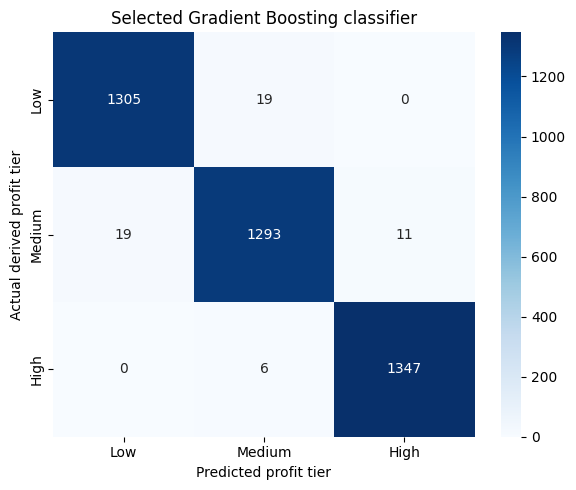

In [102]:
selected_profit = test_predictions[selected_reg_number]["profit"]
selected_priority = test_predictions[selected_cls_number]["priority"]

report = pd.DataFrame(
    classification_report(
        y_test_cls,
        selected_priority,
        labels=["Low", "Medium", "High"],
        output_dict=True,
        zero_division=0
    )
).T

display(report)

report.to_csv(
    OUT / "selected_classifier_report.csv"
)

labels = ["Low", "Medium", "High"]

matrix = confusion_matrix(
    y_test_cls,
    selected_priority,
    labels=labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted profit tier")
plt.ylabel("Actual derived profit tier")
plt.title("Selected Gradient Boosting classifier")
plt.tight_layout()

plt.savefig(
    OUT / "selected_confusion_matrix.png",
    dpi=150
)

plt.show()

> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

The selected Gradient Boosting classifier achieved its strongest class-level performance for the High profit tier, with precision of 99.190%, recall of 99.557%, and an F1-score of 0.993729. It correctly identified 1,347 of 1,353 actual High-tier records, missing six. Eleven records from other tiers were incorrectly predicted as High. The Medium tier had the lowest recall (97.732%) and F1-score (0.979175), with 30 misclassified records. Overall, 55 of 4,000 records were misclassified. These classes represent derived profit tiers, so the results do not validate independent operational priority.

Selected regressor failure cases

In [103]:
final_results = test_df.copy()

final_results["predicted_profit_usd"] = selected_profit
final_results["predicted_priority"] = selected_priority

final_results["residual_usd"] = (
    final_results["total_profit_usd"] -
    final_results["predicted_profit_usd"]
)

final_results["absolute_error_usd"] = (
    final_results["residual_usd"].abs()
)

failure_cases = final_results.nlargest(
    20,
    "absolute_error_usd"
)

display(
    failure_cases[
        [
            "device_id",
            "device_category",
            "condition",
            "total_profit_usd",
            "predicted_profit_usd",
            "absolute_error_usd"
        ]
    ]
)

category_errors = (
    final_results.groupby("device_category")
    ["absolute_error_usd"]
    .agg(["count", "mean", "median", "max"])
    .sort_values("mean", ascending=False)
)

display(category_errors)

failure_cases.to_csv(
    OUT / "selected_regression_failure_cases.csv",
    index=False
)

category_errors.to_csv(
    OUT / "selected_error_by_category.csv"
)

classification_failures = final_results.loc[
    final_results["Batch_Priority"] !=
    final_results["predicted_priority"]
]

classification_failures.to_csv(
    OUT / "selected_classification_failure_cases.csv",
    index=False
)

,device_id,device_category,condition,total_profit_usd,predicted_profit_usd,absolute_error_usd
3475,DEV-09694,Desktop Motherboard,New,61.22,56.180876,5.039124
1674,DEV-01863,Desktop Motherboard,New,61.34,56.490169,4.849831
2996,DEV-12386,Desktop Motherboard,Refurbished,56.93,61.747653,4.817653
3890,DEV-09005,Desktop Motherboard,Refurbished,68.95,73.531393,4.581393
3463,DEV-13109,Laptop,Refurbished,41.64,37.774172,3.865828
3067,DEV-05227,Desktop Motherboard,New,85.70,89.419875,3.719875
2360,DEV-05355,Desktop Motherboard,Used-Good,43.54,47.216287,3.676287
1682,DEV-08765,Desktop Motherboard,Used-Fair,50.84,47.206480,3.633520
2367,DEV-12444,Desktop Motherboard,New,43.89,47.505586,3.615586
1147,DEV-15468,Desktop Motherboard,Refurbished,62.42,65.962534,3.542534


,count,mean,median,max
device_category,,,,
Desktop Motherboard,404,1.142232,0.947514,5.039124
Laptop,428,0.715594,0.635714,3.865828
Microprocessor,395,0.459163,0.355229,1.965989
Tablet,403,0.113758,0.101259,0.551828
Digital Camera,391,0.098118,0.083896,0.539960
Hard Disk Drive,376,0.070547,0.057545,0.316760
Smartphone,377,0.053604,0.043342,0.261268
Wi-Fi Router,400,0.041404,0.032329,0.182893
RAM Module,415,0.039059,0.033192,0.225388


The selected Random Forest regressor had the highest category-level test MAE for Desktop Motherboards (USD 1.1422), followed by Laptops (USD 0.7156) and Microprocessors (USD 0.4592). Eighteen of the twenty largest absolute errors involved Desktop Motherboards, while two involved Laptops. The largest error was USD 5.0391 for DEV-09694, whose recorded profit of USD 61.22 was underestimated as USD 56.18. Higher recorded profit values may partly explain the larger dollar errors, but this requires further analysis. These findings support closer human review of motherboard and laptop estimates.

Selected regressor feature importance

In [104]:
from sklearn.inspection import permutation_importance

selected_regressor = models[selected_reg_number]["regression"]

regression_features = summaries[selected_reg_number]["regression_features"]

importance = permutation_importance(
    selected_regressor,
    X_test[regression_features],
    y_test_reg,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=2
)

importance_table = pd.DataFrame({
    "feature": regression_features,
    "MAE_increase_USD": importance.importances_mean,
    "STD_MAE_increase_USD": importance.importances_std
}).sort_values("MAE_increase_USD", ascending=False)

display(importance_table)

importance_table.to_csv(
    OUT / "selected_regression_permutation_importance.csv",
    index=False
)

,feature,MAE_increase_USD,STD_MAE_increase_USD
2,gold_yield_g,11.034607,0.175032
7,condition,2.298596,0.059678
3,silver_yield_g,0.160604,0.001638
4,copper_yield_g,0.116443,0.002648
5,Acquisition_Cost_LKR,0.058412,0.002059
0,weight_g,0.034010,0.001360
6,device_category,0.023115,0.001150
1,device_age_years,0.000666,0.001262
8,Hazardous_Flag,-0.000219,0.000346
9,Casing_Material,-0.001108,0.000431


Test-set permutation importance showed that the selected Random Forest regressor relied most strongly on gold yield and device condition. Shuffling gold yield increased MAE by USD 11.034607, while shuffling condition increased MAE by USD 2.298596. Silver and copper yields had smaller positive importance values. Device age, hazardous flag, and casing material showed little predictive contribution in this evaluation. These values describe model reliance rather than causal effects or operational safety importance. Correlated inputs may affect the rankings. No features were removed or models retrained using these test-set findings.

Profit prediction සහ tier output consistency

In [105]:
final_results["tier_from_predicted_profit"] = profit_tier(
    selected_profit
)

final_results["tier_disagreement"] = (
    final_results["tier_from_predicted_profit"] !=
    final_results["predicted_priority"]
)

print(
    "Output tier disagreements:",
    int(final_results["tier_disagreement"].sum())
)

print(
    "Disagreement percentage:",
    round(
        final_results["tier_disagreement"].mean() * 100,
        2
    )
)

display(
    final_results.loc[
        final_results["tier_disagreement"],
        [
            "device_id",
            "predicted_profit_usd",
            "tier_from_predicted_profit",
            "predicted_priority"
        ]
    ].head(10)
)

Output tier disagreements: 28
Disagreement percentage: 0.7


,device_id,predicted_profit_usd,tier_from_predicted_profit,predicted_priority
292,DEV-15085,1.578508,Medium,Low
324,DEV-14013,1.572092,Medium,Low
380,DEV-18685,1.616141,Medium,Low
426,DEV-12788,4.647800,Medium,High
436,DEV-07182,4.676591,Medium,High
551,DEV-03169,1.575322,Medium,Low
743,DEV-10677,1.604854,Medium,Low
864,DEV-15245,1.564947,Low,Medium
1368,DEV-01163,1.544798,Low,Medium
1420,DEV-02899,4.967444,High,Medium


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

The selected Random Forest regressor and Gradient Boosting classifier produced consistent profit-tier outputs for 3,972 of 4,000 test records (99.3%). For 28 records (0.7%), the tier derived from predicted profit differed from the classifier’s predicted tier. The displayed examples were close to tier boundaries, although all disagreements require inspection before generalising this observation. Agreement measures output consistency rather than predictive accuracy. Both predictions should be retained, with disagreements flagged for human review.

Final models and metadata save

In [106]:
joblib.dump(
    models[selected_reg_number]["regression"],
    OUT / "final_profit_pipeline.joblib"
)

joblib.dump(
    models[selected_cls_number]["classification"],
    OUT / "final_priority_pipeline.joblib"
)

with open(OUT / "feature_config.json", "w") as file:
    json.dump(config, file, indent=2)

final_metadata = {
    "selection": selection,
    "selected_regression_test_results": (
        test_comparison.loc[
            test_comparison["notebook"] == selected_reg_number
        ].iloc[0].to_dict()
    ),
    "selected_classification_test_results": (
        test_comparison.loc[
            test_comparison["notebook"] == selected_cls_number
        ].iloc[0].to_dict()
    ),
    "test_evaluated": True,
    "sklearn_version": sklearn.__version__,
    "tier_disagreement_count": int(
        final_results["tier_disagreement"].sum()
    ),
    "priority_meaning": "Derived profit-tier proxy",
    "models_retuned_after_test": False
}

with open(OUT / "final_model_metadata.json", "w") as file:
    json.dump(final_metadata, file, indent=2)

print("Final models, evaluation and metadata saved.")

Final models, evaluation and metadata saved.


Final interpretation and recommendation

## Final evaluation
- CV-selected models:
- Selected regression test MAE, RMSE and R²:
- Selected classification test macro-F1 and balanced accuracy:
- CV versus test differences:
- High-tier recall and important classification errors:
- High-error categories and regression failure cases:
- Profit/tier output disagreements:

## Stakeholder recommendation
Use recorded-profit estimates and profit-tier predictions as
decision support with human review.

Review uncertain measurements, hazardous items, unusual inputs
and disagreements between profit estimates and tier predictions.

## Limitations
- Metal-yield availability before purchasing needs confirmation.
- The accounting definition of recorded profit needs verification.
- Operational time, energy and contamination measurements are absent.
- Priority labels are derived from profit, not independent
  operational ground truth.
- Classification CV is conditional on the training-derived policy.
- Random holdout does not validate new suppliers or future periods.
- Predictions do not establish a verified maximum purchase price.

## Industry Explorer evidence
Add verified data provenance, permission, scope approval and
feedback from the same stakeholder. Do not invent evidence.

## AI-use transparency and contributions
Record actual assistance, verification and each member's work.

In [107]:
train_df.to_csv(
    OUT / "final_train_features.csv",
    index=False
)

test_df.to_csv(
    OUT / "final_test_features.csv",
    index=False
)

final_results.to_csv(
    OUT / "final_test_predictions.csv",
    index=False
)


> **Historical interpretation from the source notebook. Recheck against this run’s outputs.**

The models selected using training cross-validation also achieved the best held-out test performance for their respective tasks. Random Forest Regression achieved an MAE of USD 0.279727, RMSE of USD 0.581364, and R² of 0.998055, with no negative profit predictions. Its test MAE was close to its CV MAE of USD 0.279303. Gradient Boosting Classification achieved a macro-F1 of 0.986184, balanced accuracy of 0.986180, and accuracy of 98.625%, correctly classifying 3,945 of 4,000 test records. The classification target represents derived profit tiers rather than independently verified operational priorities. No models were retuned or selections changed using test results. Performance on this holdout does not establish generalisation to future periods or new suppliers.

## Export all results
The ZIP includes training evidence, CV candidates and fold scores, feature comparisons, saved pipelines, test outputs and figures. Download the executed notebook through **File → Download → Download .ipynb** to retain outputs.

In [108]:
import shutil
from pathlib import Path
# Keep the original uploaded dataset out of this evidence archive.
archive_dir = WORK.parent / 'ewaste_evidence_bundle'
archive_dir.mkdir(exist_ok=True)
for entry in WORK.iterdir():
    if entry.is_file() and entry.name != dataset_filename:
        shutil.copy2(entry, archive_dir / entry.name)
if (WORK / 'final_outputs').exists():
    shutil.copytree(WORK / 'final_outputs', archive_dir / 'final_outputs', dirs_exist_ok=True)
zip_path = shutil.make_archive(str(WORK.parent / 'E_Waste_Complete_Outputs'), 'zip', root_dir=archive_dir)
print('Evidence archive:', zip_path)
files.download(zip_path)


Evidence archive: /content/E_Waste_Complete_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>